
# STRATUM — Model Optimisation and Cross-validation

## Phase 3 — Step 3.5

### Background

Initial regression experiments identified XGBoost
as the leading mean-thickness prediction algorithm.

However, the models were evaluated using a single
chronological validation partition.

This investigation evaluates candidate performance
across multiple historical manufacturing periods.

### Objectives

1. Implement five-fold chronological expanding-window
   cross-validation.

2. Prevent lot and batch overlap between fold-training
   and fold-validation observations.

3. Compare historical baselines, bounded Ridge,
   Random Forest, and XGBoost.

4. Perform focused hyperparameter optimisation.

5. Implement training-internal XGBoost early stopping.

6. Evaluate model performance stability across time.

7. Investigate accuracy-complexity trade-offs.

8. Select a final thickness-model configuration.

### Evaluation Protocol

- Cross-validation uses the original training partition.
- All candidate configurations are defined before
  executing the cross-validation search.
- Preprocessing is fitted within each training fold.
- Early stopping uses an internal chronological split.
- Outer fold validation is used for candidate comparison.
- The original validation partition is used for
  post-selection performance assessment.
- Final test targets remain reserved until Step 3.8.

### Primary Selection Metric

Mean chronological cross-validation MAE.

Secondary diagnostics include RMSE, R2, prediction
bias, error percentiles, model size, inference latency,
and fold-to-fold performance variability.

### Limitations

Candidate configurations were informed by prior
validation experiments.

Cross-validation scores are model-development
estimates rather than independent final test results.

Expanding-window folds have overlapping training
observations and are not statistically independent.

In [1]:

# Imports

from pathlib import Path
import sys
import json
import hashlib
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (
    current_dir
    / "ml"
    / "cross_validation.py"
).exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "cross_validation.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml.data_split import chronological_lot_split
from ml.preprocessing import get_feature_columns

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.cross_validation import (
    prepare_chronological_data,
    purge_training_overlap,
    chronological_cv_folds,
    chronological_inner_split,
    get_candidate_columns,
    build_candidate_model,
    fit_candidate_model,
)

TARGET = "mean_thickness"

RANDOM_STATE = 42

N_SPLITS = 5

INITIAL_TRAIN_FRACTION = 0.4

INNER_VALIDATION_FRACTION = 0.2

EARLY_STOPPING_ROUNDS = 50

N_JOBS = -1

print("STRATUM - Model Optimisation")

print("Python:", sys.version.split()[0])

print("Scikit-learn:", sklearn.__version__)

print("XGBoost:", xgboost.__version__)

print("\nAll modules imported successfully!")

STRATUM - Model Optimisation
Python: 3.14.3
Scikit-learn: 1.9.1
XGBoost: 3.4.1

All modules imported successfully!


## 1. Dataset and Experiment Reproducibility

Verify the dataset fingerprint and reproduce
the fixed chronological, lot-aware partitions.

Load previous regression experiment results.

Reserve final test targets and conduct
hyperparameter optimisation exclusively within
the original training partition.

In [2]:

# Dataset verification

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest = json.loads(
    (
        project_root
        / "docs"
        / "split_manifest.json"
    ).read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256 == manifest["dataset_sha256"]
)

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,
        test_fraction=manifest["test_fraction"],
        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, feature_columns = (
    get_feature_columns(df)
)

assert (
    apc_features
    == manifest["numeric_apc_features"]
)

train_df = prepare_chronological_data(
    train_df
)

val_df = prepare_chronological_data(
    val_df
)

assert len(train_df) == 3331
assert len(val_df) == 834
assert len(test_df) == 1042

assert len(apc_features) == 110

assert np.isfinite(
    train_df[TARGET]
).all()

assert (
    train_df[TARGET] > 0
).all()

print("Dataset fingerprint: VERIFIED")
print("Partition manifest: VERIFIED")
print("APC schema: VERIFIED")

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Partition manifest: VERIFIED
APC schema: VERIFIED

Training records: 3331
Validation records: 834
Reserved test records: 1042


In [3]:

# Load previous benchmark experiments

results_dir = (
    project_root / "ml" / "results"
)

reference_files = {
    "Baseline": "thickness_baselines.json",

    "Ridge": (
        "thickness_linear_robustness.json"
    ),

    "Random Forest": (
        "thickness_random_forest.json"
    ),

    "XGBoost": (
        "thickness_xgboost.json"
    ),
}

reference_experiments = {}

for name, filename in reference_files.items():

    experiment = json.loads(
        (results_dir / filename)
        .read_text(encoding="utf-8")
    )

    assert (
        experiment["dataset_sha256"]
        == current_sha256
    )

    assert (
        experiment["evaluation_partition"]
        == "validation"
    )

    assert experiment["target"] == TARGET

    assert (
        experiment["training_records"]
        == len(train_df)
    )

    assert (
        experiment["validation_records"]
        == len(val_df)
    )

    reference_experiments[name] = experiment

baseline_reference_mae = float(
    reference_experiments["Baseline"][
        "best_baseline_mae"
    ]
)

ridge_reference_mae = float(
    reference_experiments["Ridge"][
        "best_model_mae"
    ]
)

forest_reference_mae = float(
    reference_experiments["Random Forest"][
        "best_model_mae"
    ]
)

xgb_reference_mae = float(
    reference_experiments["XGBoost"][
        "best_model_mae"
    ]
)

print(
    "Equipment Mean:",
    baseline_reference_mae
)

print(
    "Bounded Ridge:",
    ridge_reference_mae
)

print(
    "Random Forest:",
    forest_reference_mae
)

print(
    "XGBoost:",
    xgb_reference_mae
)

print("\nPrevious experiments verified.")

Equipment Mean: 1.9954786118972963
Bounded Ridge: 1.2677876572335938
Random Forest: 1.158246551146896
XGBoost: 1.0790623717414562

Previous experiments verified.


## 2. Original Partition Leakage Audit

Investigate lot and batch overlap between the
original training and validation partitions.

Preserve the original validation records.

If overlap exists, remove affected historical
training observations for the post-selection
validation assessment.

Do not modify the original split manifest.

In [4]:

# Original partition overlap audit

partition_overlap_rows = []

for column in ["wafer_id", "lot", "bat_id"]:

    train_groups = set(
        train_df[column].dropna()
    )

    val_groups = set(
        val_df[column].dropna()
    )

    overlapping_groups = (
        train_groups & val_groups
    )

    partition_overlap_rows.append({
        "Identifier": column,

        "Training Unique": len(
            train_groups
        ),

        "Validation Unique": len(
            val_groups
        ),

        "Overlapping Groups": len(
            overlapping_groups
        ),

        "Affected Training Records": int(
            train_df[column]
            .isin(overlapping_groups)
            .sum()
        ),
    })

partition_overlap_df = pd.DataFrame(
    partition_overlap_rows
)

display(partition_overlap_df)

assert (
    partition_overlap_df.loc[
        partition_overlap_df["Identifier"]
        .isin(["wafer_id", "lot"]),
        "Overlapping Groups",
    ] == 0
).all()

# Prepare historical training data for the later
# original-validation assessment.

assessment_train_df, assessment_purge_info = (
    purge_training_overlap(
        train_df,
        val_df,
    )
)

print(
    "Original training records:",
    len(train_df)
)

print(
    "Post-selection assessment training records:",
    len(assessment_train_df)
)

print(
    "Purged training records:",
    assessment_purge_info["purged_records"]
)

,Identifier,Training Unique,Validation Unique,Overlapping Groups,Affected Training Records
0,wafer_id,3331,834,0,0
1,lot,1874,487,0,0
2,bat_id,3331,834,0,0


Original training records: 3331
Post-selection assessment training records: 3331
Purged training records: 0


## 3. Chronological Expanding-Window Cross-validation

Construct five expanding-window folds within
the original training partition.

Use approximately 40% of observations for
the initial historical training window.

Divide the remaining chronological observations
into five validation windows.

Remove overlapping lots, batches and boundary
timestamps from fold-training observations.

All fold-validation records are retained.

In [5]:

# Create chronological folds

folds = chronological_cv_folds(
    train_df,
    n_splits=N_SPLITS,
    initial_train_fraction=(
        INITIAL_TRAIN_FRACTION
    ),
)

fold_summary_df = pd.DataFrame([
    fold["info"]
    for fold in folds
])

display(
    fold_summary_df[
        [
            "fold",
            "initial_training_records",
            "training_records",
            "validation_records",
            "purged_records",
            "training_start",
            "training_end",
            "validation_start",
            "validation_end",
        ]
    ]
)

print(
    "\nTotal cross-validation folds:",
    len(folds)
)

assert len(folds) == N_SPLITS

print(
    "Total CV validation observations:",
    sum(
        len(fold["validation"])
        for fold in folds
    )
)

,fold,initial_training_records,training_records,validation_records,purged_records,training_start,training_end,validation_start,validation_end
0,1,1336,1334,399,2,2021-07-31 06:51:54,2022-09-07 16:02:56,2022-09-08 17:40:07,2023-01-05 07:34:27
1,2,1735,1734,399,1,2021-07-31 06:51:54,2023-01-04 11:01:21,2023-01-05 07:35:58,2023-04-27 23:00:49
2,3,2134,2133,399,1,2021-07-31 06:51:54,2023-04-27 08:13:18,2023-04-27 23:02:42,2023-07-16 15:48:28
3,4,2533,2531,399,2,2021-07-31 06:51:54,2023-07-16 15:03:13,2023-07-16 15:50:54,2023-10-03 16:46:30
4,5,2932,2931,399,1,2021-07-31 06:51:54,2023-10-03 08:07:11,2023-10-03 16:47:48,2023-12-26 05:13:18



Total cross-validation folds: 5
Total CV validation observations: 1995


In [6]:

# Verify every fold

all_cv_validation_ids = []

for fold in folds:

    fold_train = fold["train"]

    fold_val = fold["validation"]

    assert (
        fold_train["runstart"].max()
        < fold_val["runstart"].min()
    )

    for column in [
        "wafer_id",
        "lot",
        "bat_id",
    ]:

        assert set(
            fold_train[column]
        ).isdisjoint(
            set(fold_val[column])
        )

    assert set(
        fold_train["wafer_id"]
    ).issubset(
        set(train_df["wafer_id"])
    )

    assert set(
        fold_val["wafer_id"]
    ).issubset(
        set(train_df["wafer_id"])
    )

    all_cv_validation_ids.extend(
        fold_val["wafer_id"].tolist()
    )

    print(
        f"Fold {fold['fold']}: "
        f"chronology, lot and batch checks PASSED"
    )

assert len(
    all_cv_validation_ids
) == len(
    set(all_cv_validation_ids)
)

print(
    "\nAll outer-fold leakage checks: PASSED"
)

Fold 1: chronology, lot and batch checks PASSED
Fold 2: chronology, lot and batch checks PASSED
Fold 3: chronology, lot and batch checks PASSED
Fold 4: chronology, lot and batch checks PASSED
Fold 5: chronology, lot and batch checks PASSED

All outer-fold leakage checks: PASSED


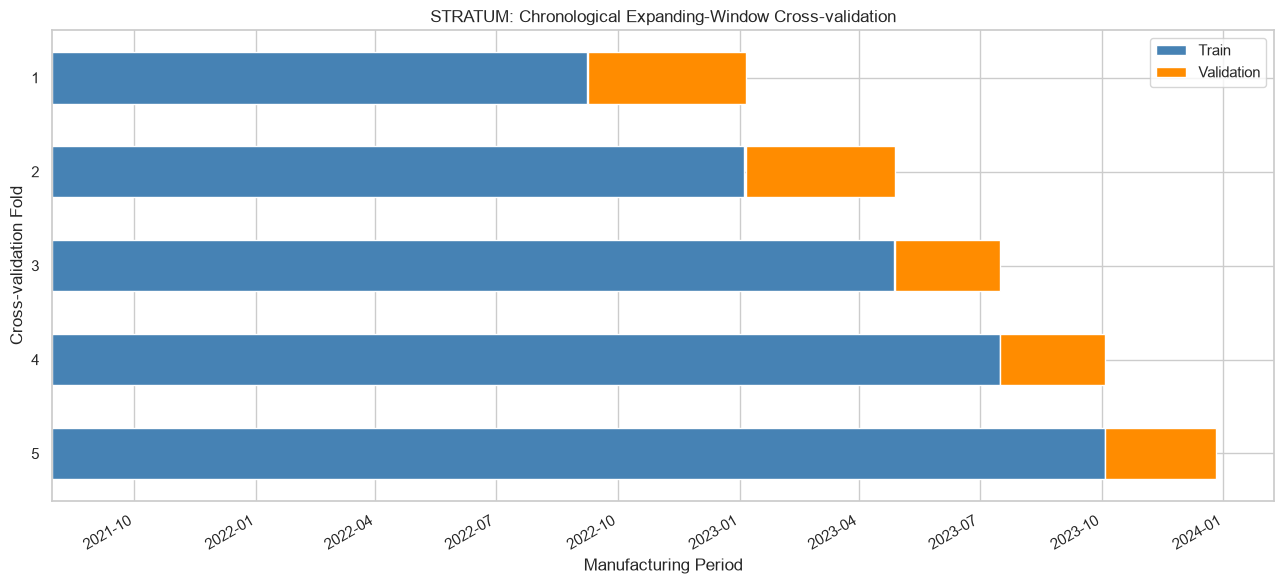

In [7]:

# Plot chronological CV windows

import matplotlib.dates as mdates

fig, ax = plt.subplots(
    figsize=(13, 6)
)

for fold in folds:

    fold_number = fold["fold"]

    for partition, color in [
        ("train", "steelblue"),
        ("validation", "darkorange"),
    ]:

        subset = fold[partition]

        start = mdates.date2num(
            subset["runstart"].min()
        )

        end = mdates.date2num(
            subset["runstart"].max()
        )

        ax.barh(
            fold_number,
            end - start,
            left=start,
            height=0.55,
            color=color,
            label=(
                partition.title()
                if fold_number == 1
                else None
            ),
        )

ax.set_yticks(
    range(1, N_SPLITS + 1)
)

ax.invert_yaxis()

ax.xaxis_date()

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

ax.set_title(
    "STRATUM: Chronological Expanding-Window "
    "Cross-validation"
)

ax.set_xlabel("Manufacturing Period")

ax.set_ylabel("Cross-validation Fold")

ax.legend()

fig.autofmt_xdate()

plt.tight_layout()
plt.show()

## 4. Internal Early-Stopping Partition Verification

Within each outer training window, create a
chronological inner training-validation split.

Use the final approximately 20% of the outer
training observations for boosting-round selection.

Remove overlapping lots and batches from
inner-training observations.

Outer-validation targets remain unavailable
to the early-stopping procedure.

In [8]:

# Verify internal early-stopping partitions

inner_fold_rows = []

for fold in folds:

    inner_train, inner_val, purge_info = (
        chronological_inner_split(
            fold["train"],
            validation_fraction=(
                INNER_VALIDATION_FRACTION
            ),
        )
    )

    assert (
        inner_train["runstart"].max()
        < inner_val["runstart"].min()
    )

    for column in [
        "lot",
        "bat_id",
        "wafer_id",
    ]:

        assert set(
            inner_train[column]
        ).isdisjoint(
            set(inner_val[column])
        )

        assert set(
            inner_val[column]
        ).isdisjoint(
            set(fold["validation"][column])
        )

    inner_fold_rows.append({
        "Fold": fold["fold"],

        "Inner Training": len(
            inner_train
        ),

        "Inner Validation": len(
            inner_val
        ),

        "Purged Records": purge_info[
            "purged_records"
        ],

        "Inner Training End": str(
            inner_train["runstart"].max()
        ),

        "Inner Validation Start": str(
            inner_val["runstart"].min()
        ),
    })

inner_fold_summary = pd.DataFrame(
    inner_fold_rows
)

display(inner_fold_summary)

print(
    "All inner-fold early-stopping checks: PASSED"
)

,Fold,Inner Training,Inner Validation,Purged Records,Inner Training End,Inner Validation Start
0,1,1066,267,1,2022-06-17 20:10:37,2022-06-17 21:12:13
1,2,1385,347,2,2022-09-28 05:19:41,2022-09-28 16:38:26
2,3,1706,427,0,2022-12-25 15:40:16,2022-12-25 18:33:36
3,4,2023,507,1,2023-04-02 05:20:28,2023-04-02 05:40:45
4,5,2343,587,1,2023-06-14 06:02:37,2023-06-14 09:08:47


All inner-fold early-stopping checks: PASSED


## 5. Predefined Hyperparameter Search Space

Evaluate 19 candidate configurations:

- One historical equipment-mean baseline.
- Four bounded Ridge configurations.
- Four Random Forest configurations.
- Ten XGBoost configurations.

The search space is informed by previous
model-development experiments.

Candidate configurations are fixed before
cross-validation execution.

This is a focused parameter search rather
than an exhaustive optimisation.

In [9]:

# Define the complete candidate search space

candidates = []


def add_candidate(
    name,
    algorithm,
    include_equipment,
    **parameters,
):

    candidates.append({
        "name": name,
        "algorithm": algorithm,
        "include_equipment": include_equipment,
        "parameters": parameters,
    })


# Historical baseline

add_candidate(
    "Equipment Mean",
    "Equipment Mean",
    True,
)


# Bounded Ridge candidates

for name, include_equipment, alpha, clip in [
    ("Ridge-1", True, 10.0, 5.0),
    ("Ridge-2", False, 10.0, 5.0),
    ("Ridge-3", True, 100.0, 5.0),
    ("Ridge-4", True, 10.0, 8.0),
]:

    add_candidate(
        name,
        "Ridge",
        include_equipment,
        alpha=alpha,
        clip_z=clip,
    )


# Random Forest candidates

for name, include_equipment, trees, depth, leaf in [
    ("RF-1", True, 200, None, 1),
    ("RF-2", False, 200, None, 1),
    ("RF-3", True, 200, 12, 2),
    ("RF-4", True, 300, 16, 2),
]:

    add_candidate(
        name,
        "Random Forest",
        include_equipment,
        n_estimators=trees,
        max_depth=depth,
        min_samples_leaf=leaf,
        max_features=0.7,
        random_state=RANDOM_STATE,
    )


# XGBoost candidates
#
# Fields:
# name, equipment, missing strategy, depth,
# learning rate, maximum rounds, child weight,
# L1 regularisation, L2 regularisation

xgb_search_space = [
    (
        "XGB-1", True, "median",
        3, 0.10, 900, 1, 0.0, 1.0,
    ),
    (
        "XGB-2", False, "median",
        3, 0.10, 900, 1, 0.0, 1.0,
    ),
    (
        "XGB-3", True, "median",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "XGB-4", False, "median",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "XGB-5", True, "native",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "XGB-6", False, "native",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "XGB-7", True, "median",
        3, 0.05, 1200, 3, 0.1, 3.0,
    ),
    (
        "XGB-8", True, "median",
        4, 0.05, 1000, 5, 0.1, 5.0,
    ),
    (
        "XGB-9", True, "median",
        5, 0.05, 1000, 5, 0.1, 5.0,
    ),
    (
        "XGB-10", True, "median",
        4, 0.025, 1500, 10, 0.5, 10.0,
    ),
]

for (
    name,
    include_equipment,
    missing_strategy,
    depth,
    learning_rate,
    rounds,
    child_weight,
    reg_alpha,
    reg_lambda,
) in xgb_search_space:

    add_candidate(
        name,
        "XGBoost",
        include_equipment,
        missing_strategy=missing_strategy,
        max_depth=depth,
        learning_rate=learning_rate,
        n_estimators=rounds,
        min_child_weight=child_weight,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=0.0,
        random_state=RANDOM_STATE,
    )

candidate_lookup = {
    candidate["name"]: candidate
    for candidate in candidates
}

assert len(candidates) == 19
assert len(candidate_lookup) == 19

candidate_summary_df = pd.json_normalize(
    candidates
)

display(candidate_summary_df)

print(
    "Total candidates:",
    len(candidates)
)

print(
    "Total planned candidate-fold evaluations:",
    len(candidates) * len(folds)
)

,name,algorithm,include_equipment,parameters.alpha,parameters.clip_z,parameters.n_estimators,parameters.max_depth,parameters.min_samples_leaf,parameters.max_features,parameters.random_state,parameters.missing_strategy,parameters.learning_rate,parameters.min_child_weight,parameters.reg_alpha,parameters.reg_lambda,parameters.subsample,parameters.colsample_bytree,parameters.gamma
0,Equipment Mean,Equipment Mean,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ridge-1,Ridge,True,10.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Ridge-2,Ridge,False,10.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ridge-3,Ridge,True,100.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Ridge-4,Ridge,True,10.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,RF-1,Random Forest,True,NaN,NaN,200.0,NaN,1.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,RF-2,Random Forest,False,NaN,NaN,200.0,NaN,1.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,RF-3,Random Forest,True,NaN,NaN,200.0,12.0,2.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,RF-4,Random Forest,True,NaN,NaN,300.0,16.0,2.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,XGB-1,XGBoost,True,NaN,NaN,900.0,3.0,NaN,NaN,42.0,median,0.100,1.0,0.0,1.0,0.8,0.8,0.0


Total candidates: 19
Total planned candidate-fold evaluations: 95


In [10]:

# Check model construction before starting training

for candidate in candidates:

    model = build_candidate_model(
        candidate=candidate,
        apc_features=apc_features,
        n_jobs=N_JOBS,
    )

    columns = get_candidate_columns(
        candidate,
        apc_features,
    )

    assert TARGET not in columns

    assert "mean_resistance" not in columns

    assert set(columns).issubset(
        set(train_df.columns)
    )

    print(
        candidate["name"],
        "->",
        type(model).__name__,
        "| Inputs:",
        len(columns),
    )

print(
    "\nAll candidate construction checks: PASSED"
)

Equipment Mean -> EquipmentMeanRegressor | Inputs: 1
Ridge-1 -> Pipeline | Inputs: 111
Ridge-2 -> Pipeline | Inputs: 110
Ridge-3 -> Pipeline | Inputs: 111
Ridge-4 -> Pipeline | Inputs: 111
RF-1 -> Pipeline | Inputs: 111
RF-2 -> Pipeline | Inputs: 110
RF-3 -> Pipeline | Inputs: 111
RF-4 -> Pipeline | Inputs: 111
XGB-1 -> Pipeline | Inputs: 111
XGB-2 -> Pipeline | Inputs: 110
XGB-3 -> Pipeline | Inputs: 111
XGB-4 -> Pipeline | Inputs: 110
XGB-5 -> Pipeline | Inputs: 111
XGB-6 -> Pipeline | Inputs: 110
XGB-7 -> Pipeline | Inputs: 111
XGB-8 -> Pipeline | Inputs: 111
XGB-9 -> Pipeline | Inputs: 111
XGB-10 -> Pipeline | Inputs: 111

All candidate construction checks: PASSED


## 6. Chronological Cross-validation Execution

Train every candidate independently within each
chronological fold.

Evaluate predictions exclusively on that fold's
later validation observations.

Record:

- Training and validation MAE.
- RMSE, R2, MAPE and signed bias.
- Maximum and P95 absolute error.
- Non-positive predictions.
- Training-validation generalisation gap.
- Selected XGBoost boosting rounds.
- Training and prediction time.

Preserve aligned out-of-fold predictions for
development-stage comparative diagnostics.

In [11]:

# Execute the cross-validation search

cv_results = []

oof_predictions = []

total_evaluations = (
    len(candidates) * len(folds)
)

evaluation_number = 0

search_start = time.perf_counter()

for candidate in candidates:

    candidate_name = candidate["name"]

    columns = get_candidate_columns(
        candidate,
        apc_features,
    )

    for fold in folds:

        evaluation_number += 1

        fold_train = fold["train"]

        fold_val = fold["validation"]

        print(
            f"[{evaluation_number}/"
            f"{total_evaluations}] "
            f"{candidate_name} - "
            f"Fold {fold['fold']}",
            flush=True,
        )

        start = time.perf_counter()

        model, fit_info = fit_candidate_model(
            candidate=candidate,
            training_data=fold_train,
            apc_features=apc_features,
            target=TARGET,
            n_jobs=N_JOBS,
            early_stopping_rounds=(
                EARLY_STOPPING_ROUNDS
            ),
            inner_validation_fraction=(
                INNER_VALIDATION_FRACTION
            ),
        )

        training_time = (
            time.perf_counter() - start
        )

        training_predictions = np.asarray(
            model.predict(
                fold_train[columns]
            )
        )

        start = time.perf_counter()

        predictions = np.asarray(
            model.predict(
                fold_val[columns]
            )
        )

        prediction_time = (
            time.perf_counter() - start
        )

        actual = fold_val[TARGET].to_numpy()

        assert predictions.shape == actual.shape

        assert np.isfinite(predictions).all()

        assert np.isfinite(
            training_predictions
        ).all()

        training_metrics = evaluate_regression(
            fold_train[TARGET],
            training_predictions,
        )

        metrics = evaluate_regression(
            actual,
            predictions,
        )

        absolute_errors = np.abs(
            actual - predictions
        )

        result = {
            "Candidate": candidate_name,

            "Algorithm": candidate["algorithm"],

            "Include Equipment": candidate[
                "include_equipment"
            ],

            "Fold": fold["fold"],

            "Training Records": len(
                fold_train
            ),

            "Validation Records": len(
                fold_val
            ),

            "Training MAE": (
                training_metrics["MAE"]
            ),

            **metrics,

            "Generalisation Gap": (
                metrics["MAE"]
                - training_metrics["MAE"]
            ),

            "Maximum Absolute Error": float(
                absolute_errors.max()
            ),

            "P95 Absolute Error": float(
                np.quantile(
                    absolute_errors, 0.95
                )
            ),

            "Non-Positive Predictions": int(
                (predictions <= 0).sum()
            ),

            "Training Time (s)": training_time,

            "Prediction Time (s)": prediction_time,

            **fit_info,
        }

        cv_results.append(result)

        prediction_frame = pd.DataFrame({
            "Candidate": candidate_name,

            "Algorithm": candidate[
                "algorithm"
            ],

            "Fold": fold["fold"],

            "wafer_id": fold_val[
                "wafer_id"
            ].to_numpy(),

            "lot": fold_val[
                "lot"
            ].to_numpy(),

            "equipment": fold_val[
                "equipment"
            ].to_numpy(),

            "Actual": actual,

            "Predicted": predictions,

            "Absolute Error": absolute_errors,
        })

        oof_predictions.append(
            prediction_frame
        )

        print(
            f"  MAE: {metrics['MAE']:.6f} | "
            f"RMSE: {metrics['RMSE']:.6f} | "
            f"R2: {metrics['R2']:.6f} | "
            f"Time: {training_time:.2f}s",
            flush=True,
        )

        if (
            fit_info[
                "selected_boosting_rounds"
            ] is not None
        ):

            print(
                "  Selected boosting rounds:",
                fit_info[
                    "selected_boosting_rounds"
                ],
                flush=True,
            )

        del model

search_elapsed = (
    time.perf_counter() - search_start
)

cv_results_df = pd.DataFrame(
    cv_results
)

oof_predictions_df = pd.concat(
    oof_predictions,
    ignore_index=True,
)

assert len(cv_results_df) == total_evaluations

print("\nCross-validation search completed.")

print(
    "Completed evaluations:",
    len(cv_results_df)
)

print(
    "Total elapsed seconds:",
    round(search_elapsed, 2)
)

display(
    cv_results_df.head().round(6)
)

[1/95] Equipment Mean - Fold 1
  MAE: 1.944481 | RMSE: 2.541927 | R2: -0.057117 | Time: 0.00s
[2/95] Equipment Mean - Fold 2
  MAE: 2.161639 | RMSE: 2.832175 | R2: -0.181432 | Time: 0.00s
[3/95] Equipment Mean - Fold 3
  MAE: 2.046024 | RMSE: 2.662090 | R2: 0.034738 | Time: 0.00s
[4/95] Equipment Mean - Fold 4
  MAE: 1.866310 | RMSE: 2.413159 | R2: -0.165661 | Time: 0.00s
[5/95] Equipment Mean - Fold 5
  MAE: 1.807118 | RMSE: 2.234320 | R2: -0.068001 | Time: 0.00s
[6/95] Ridge-1 - Fold 1
  MAE: 1.416204 | RMSE: 1.816938 | R2: 0.459896 | Time: 0.72s
[7/95] Ridge-1 - Fold 2
  MAE: 1.322447 | RMSE: 1.717731 | R2: 0.565411 | Time: 1.17s
[8/95] Ridge-1 - Fold 3
  MAE: 1.316235 | RMSE: 1.800771 | R2: 0.558310 | Time: 0.36s
[9/95] Ridge-1 - Fold 4
  MAE: 1.434889 | RMSE: 1.816761 | R2: 0.339312 | Time: 0.16s
[10/95] Ridge-1 - Fold 5
  MAE: 1.116445 | RMSE: 1.463681 | R2: 0.541674 | Time: 0.70s
[11/95] Ridge-2 - Fold 1
  MAE: 1.376165 | RMSE: 1.776322 | R2: 0.483774 | Time: 0.11s
[12/95] Ridge

,Candidate,Algorithm,Include Equipment,Fold,Training Records,Validation Records,Training MAE,MAE,RMSE,R2,...,P95 Absolute Error,Non-Positive Predictions,Training Time (s),Prediction Time (s),selected_boosting_rounds,inner_training_records,inner_validation_records,inner_purged_records,boosting_budget_reached,inner_best_mae
0,Equipment Mean,Equipment Mean,True,1,1334,399,1.840176,1.944481,2.541927,-0.057117,...,5.283342,0,0.003104,0.001554,NaN,NaN,NaN,NaN,None,NaN
1,Equipment Mean,Equipment Mean,True,2,1734,399,1.839305,2.161639,2.832175,-0.181432,...,5.572545,0,0.002683,0.000887,NaN,NaN,NaN,NaN,None,NaN
2,Equipment Mean,Equipment Mean,True,3,2133,399,1.882113,2.046024,2.662090,0.034738,...,5.141818,0,0.002003,0.000820,NaN,NaN,NaN,NaN,None,NaN
3,Equipment Mean,Equipment Mean,True,4,2531,399,1.893708,1.866310,2.413159,-0.165661,...,5.087849,0,0.002523,0.000707,NaN,NaN,NaN,NaN,None,NaN
4,Equipment Mean,Equipment Mean,True,5,2931,399,1.870622,1.807118,2.234320,-0.068001,...,4.507725,0,0.001960,0.000693,NaN,NaN,NaN,NaN,None,NaN


## 7. Cross-validation Performance Summary

Aggregate candidate performance across the five
chronological validation windows.

Use mean fold MAE as the primary selection metric.

Report fold-level standard deviation, worst-fold MAE,
mean RMSE, mean R2, prediction bias and
generalisation gaps.

Fold standard deviation is a descriptive measure
of temporal performance variability, not a
confidence interval.

In [12]:

# Aggregate the cross-validation results

cv_summary = (
    cv_results_df
    .groupby(
        ["Candidate", "Algorithm"],
        as_index=False,
    )
    .agg(
        Folds=("Fold", "count"),

        Mean_CV_MAE=("MAE", "mean"),

        Std_CV_MAE=("MAE", "std"),

        Best_Fold_MAE=("MAE", "min"),

        Worst_Fold_MAE=("MAE", "max"),

        Mean_CV_RMSE=("RMSE", "mean"),

        Mean_CV_R2=("R2", "mean"),

        Mean_CV_MAPE=("MAPE (%)", "mean"),

        Mean_Bias=("Bias", "mean"),

        Mean_Training_MAE=(
            "Training MAE", "mean"
        ),

        Mean_Generalisation_Gap=(
            "Generalisation Gap", "mean"
        ),

        Maximum_Absolute_Error=(
            "Maximum Absolute Error", "max"
        ),

        Non_Positive_Predictions=(
            "Non-Positive Predictions", "sum"
        ),

        Mean_Training_Time=(
            "Training Time (s)", "mean"
        ),
    )
)

baseline_cv_mae = float(
    cv_summary.loc[
        cv_summary["Candidate"]
        == "Equipment Mean",
        "Mean_CV_MAE",
    ].iloc[0]
)

cv_summary[
    "Improvement_vs_Baseline_Pct"
] = (
    (
        baseline_cv_mae
        - cv_summary["Mean_CV_MAE"]
    )
    / baseline_cv_mae
    * 100
)

cv_summary = (
    cv_summary
    .sort_values("Mean_CV_MAE")
    .reset_index(drop=True)
)

assert (
    cv_summary["Folds"] == N_SPLITS
).all()

display(cv_summary.round(6))

print(
    "Cross-validated historical baseline MAE:",
    baseline_cv_mae
)

,Candidate,Algorithm,Folds,Mean_CV_MAE,Std_CV_MAE,Best_Fold_MAE,Worst_Fold_MAE,Mean_CV_RMSE,Mean_CV_R2,Mean_CV_MAPE,Mean_Bias,Mean_Training_MAE,Mean_Generalisation_Gap,Maximum_Absolute_Error,Non_Positive_Predictions,Mean_Training_Time,Improvement_vs_Baseline_Pct
0,XGB-4,XGBoost,5,1.209290,0.123581,1.058438,1.353097,1.609894,0.563257,0.795965,0.127720,0.509283,0.700007,9.948658,0,3.583845,38.462110
1,XGB-10,XGBoost,5,1.213018,0.118511,1.071296,1.331476,1.614267,0.561146,0.798471,0.127532,0.540274,0.672745,9.993882,0,3.627617,38.272373
2,XGB-6,XGBoost,5,1.213300,0.116075,1.080545,1.342015,1.612657,0.561894,0.798568,0.127675,0.474875,0.738426,10.118012,0,5.434211,38.258029
3,XGB-3,XGBoost,5,1.214348,0.123586,1.064100,1.347996,1.617113,0.559928,0.799212,0.125064,0.555395,0.658952,10.299485,0,3.664560,38.204737
4,XGB-9,XGBoost,5,1.214356,0.134130,1.077512,1.379531,1.609881,0.562386,0.799217,0.124819,0.385685,0.828672,9.910172,0,2.966238,38.204288
5,XGB-5,XGBoost,5,1.220947,0.138510,1.063922,1.378079,1.629739,0.553319,0.803548,0.127144,0.613567,0.607380,10.499268,0,3.630160,37.868918
6,XGB-8,XGBoost,5,1.222129,0.120917,1.085435,1.357244,1.619657,0.558624,0.804365,0.118318,0.435528,0.786602,9.969223,0,2.334042,37.808744
7,XGB-1,XGBoost,5,1.245121,0.148626,1.055731,1.412223,1.672243,0.530764,0.819219,0.094730,0.650314,0.594807,11.424977,0,1.567490,36.638744
8,XGB-7,XGBoost,5,1.246596,0.134633,1.078729,1.377709,1.657560,0.538021,0.820053,0.092382,0.677726,0.568870,10.622055,0,1.671185,36.563681
9,XGB-2,XGBoost,5,1.273792,0.161818,1.088102,1.480467,1.692967,0.519164,0.838186,0.108172,0.637951,0.635841,10.404099,0,1.137358,35.179757


Cross-validated historical baseline MAE: 1.9651143736185213


In [13]:

# Calculate pooled out-of-fold regression metrics

pooled_rows = []

for candidate_name, group in (
    oof_predictions_df.groupby("Candidate")
):

    assert group["wafer_id"].is_unique

    assert len(group) == len(
        all_cv_validation_ids
    )

    metrics = evaluate_regression(
        group["Actual"],
        group["Predicted"],
    )

    pooled_rows.append({
        "Candidate": candidate_name,

        "OOF Records": len(group),

        **metrics,
    })

pooled_metrics_df = pd.DataFrame(
    pooled_rows
)

display(
    pooled_metrics_df
    .sort_values("MAE")
    .round(6)
)

,Candidate,OOF Records,MAE,RMSE,R2,MAPE (%),Bias
13,XGB-4,1995,1.209290,1.619644,0.567883,0.795965,0.127720
10,XGB-10,1995,1.213018,1.624254,0.565420,0.798471,0.127532
15,XGB-6,1995,1.213300,1.622142,0.566549,0.798568,0.127675
12,XGB-3,1995,1.214348,1.627454,0.563706,0.799212,0.125064
18,XGB-9,1995,1.214356,1.621170,0.567069,0.799217,0.124819
14,XGB-5,1995,1.220947,1.641652,0.556060,0.803548,0.127144
17,XGB-8,1995,1.222129,1.629811,0.562441,0.804365,0.118318
9,XGB-1,1995,1.245121,1.686265,0.531603,0.819219,0.094730
16,XGB-7,1995,1.246596,1.668200,0.541585,0.820053,0.092382
11,XGB-2,1995,1.273792,1.706125,0.520505,0.838186,0.108172


## 8. Cross-validation Performance Visualisation

Compare mean validation MAE and fold-to-fold
performance variability across candidate models.

Investigate whether the strongest mean-performing
candidate is also stable across manufacturing periods.

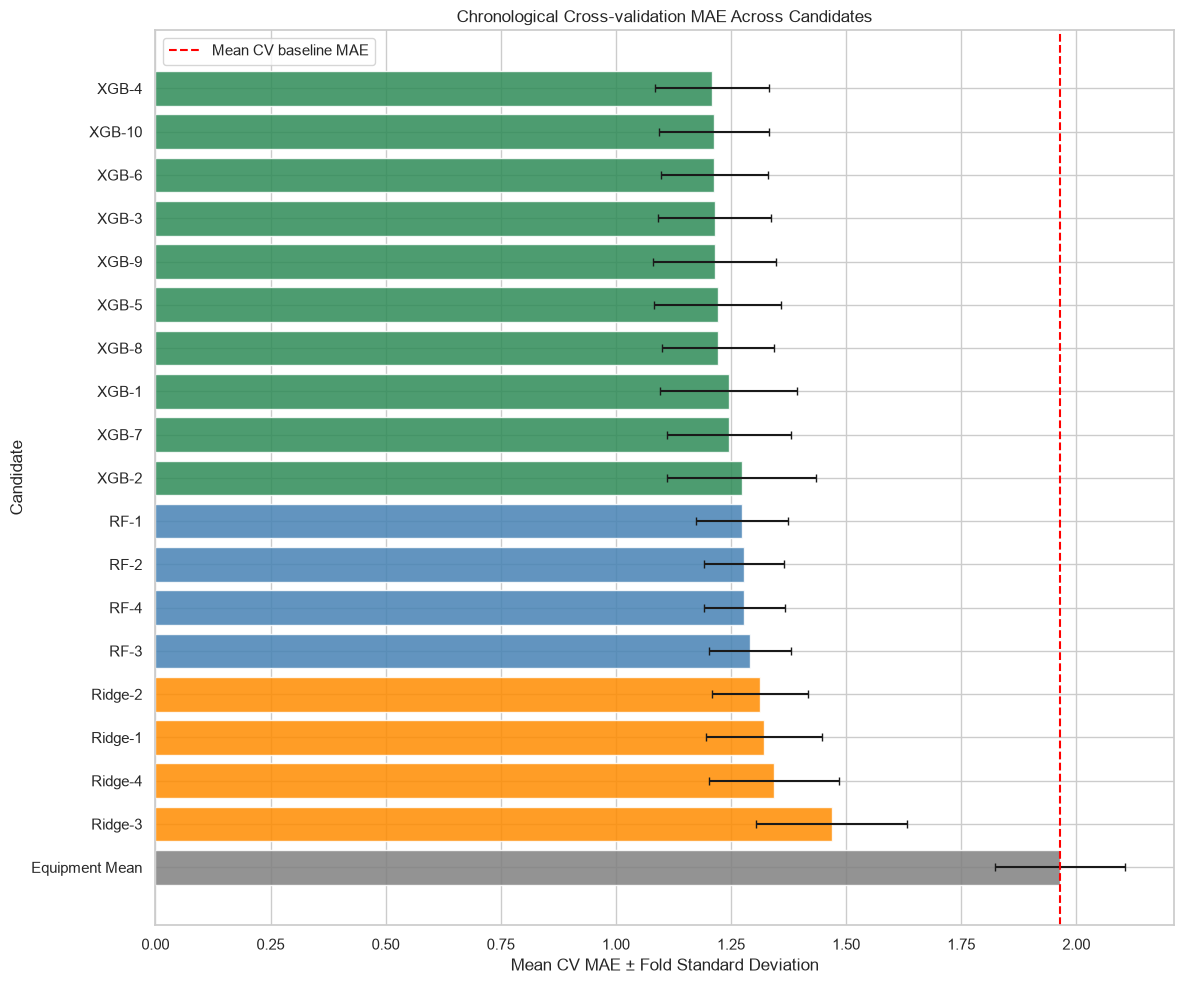

In [14]:

# Compare CV performance and variability

plot_data = (
    cv_summary
    .sort_values("Mean_CV_MAE")
    .reset_index(drop=True)
)

algorithm_colors = {
    "Equipment Mean": "grey",
    "Ridge": "darkorange",
    "Random Forest": "steelblue",
    "XGBoost": "seagreen",
}

fig, ax = plt.subplots(
    figsize=(12, 10)
)

ax.barh(
    plot_data["Candidate"],
    plot_data["Mean_CV_MAE"],

    xerr=plot_data["Std_CV_MAE"],

    color=[
        algorithm_colors[algorithm]

        for algorithm
        in plot_data["Algorithm"]
    ],

    alpha=0.85,
    capsize=3,
)

ax.invert_yaxis()

ax.axvline(
    baseline_cv_mae,
    color="red",
    linestyle="--",
    label="Mean CV baseline MAE",
)

ax.set_title(
    "Chronological Cross-validation MAE "
    "Across Candidates"
)

ax.set_xlabel(
    "Mean CV MAE ± Fold Standard Deviation"
)

ax.set_ylabel("Candidate")

ax.legend()

plt.tight_layout()
plt.show()

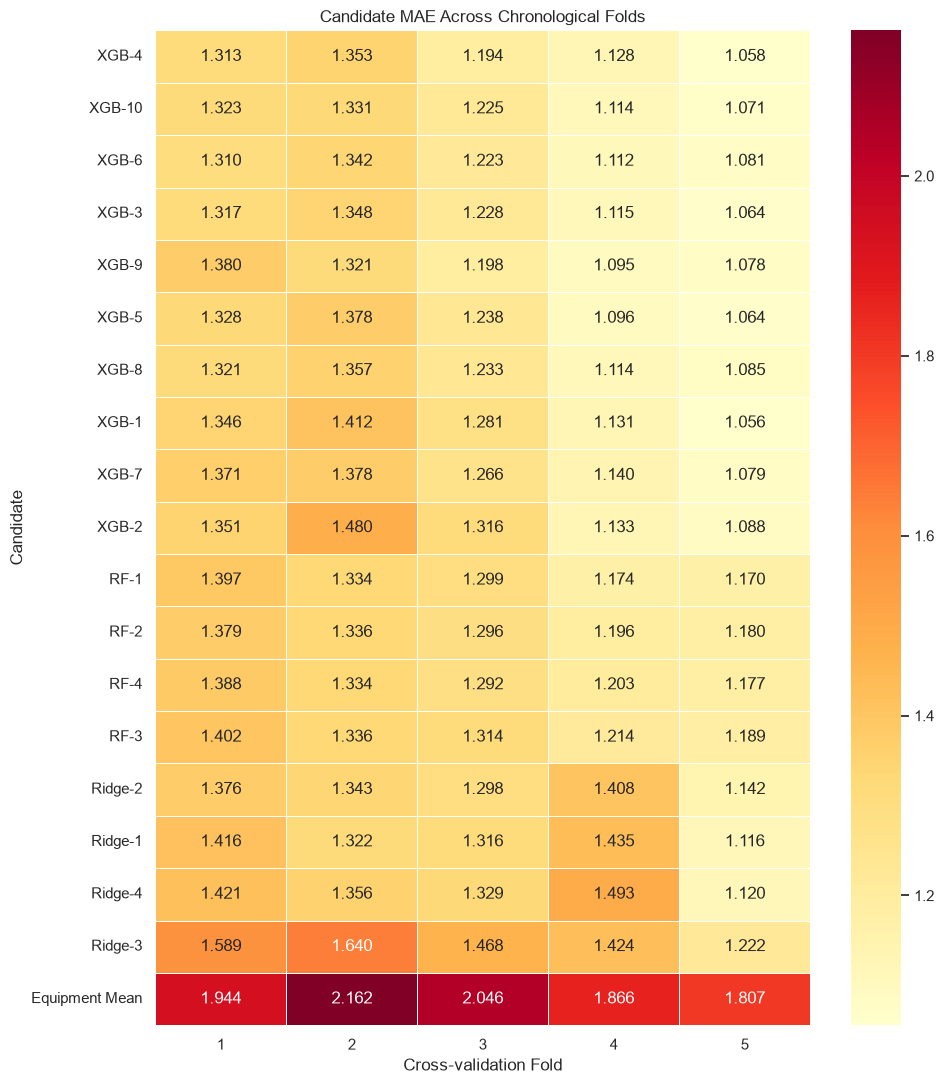

In [15]:

# Compare candidates across individual folds

fold_mae_matrix = (
    cv_results_df.pivot(
        index="Candidate",
        columns="Fold",
        values="MAE",
    )
    .reindex(
        cv_summary["Candidate"]
    )
)

plt.figure(figsize=(10, 11))

sns.heatmap(
    fold_mae_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
)

plt.title(
    "Candidate MAE Across Chronological Folds"
)

plt.xlabel("Cross-validation Fold")
plt.ylabel("Candidate")

plt.tight_layout()
plt.show()

In [16]:

# Evaluate improvement relative to the matched baseline

baseline_fold_mae = (
    cv_results_df.loc[
        cv_results_df["Candidate"]
        == "Equipment Mean",
        ["Fold", "MAE"],
    ]
    .rename(
        columns={
            "MAE": "Baseline Fold MAE"
        }
    )
)

fold_improvement_df = (
    cv_results_df.merge(
        baseline_fold_mae,
        on="Fold",
        validate="many_to_one",
    )
)

fold_improvement_df[
    "Improvement (%)"
] = (
    (
        fold_improvement_df[
            "Baseline Fold MAE"
        ]
        - fold_improvement_df["MAE"]
    )
    / fold_improvement_df[
        "Baseline Fold MAE"
    ]
    * 100
)

fold_improvement_summary = (
    fold_improvement_df
    .groupby("Candidate")
    .agg(
        Mean_Improvement=(
            "Improvement (%)", "mean"
        ),

        Minimum_Improvement=(
            "Improvement (%)", "min"
        ),

        Folds_Beating_Baseline=(
            "Improvement (%)",
            lambda values: int(
                (values > 0).sum()
            ),
        ),
    )
    .sort_values(
        "Mean_Improvement",
        ascending=False,
    )
)

display(
    fold_improvement_summary.round(6)
)

,Mean_Improvement,Minimum_Improvement,Folds_Beating_Baseline
Candidate,,,
XGB-4,38.503475,32.472657,5
XGB-10,38.300838,31.947743,5
XGB-6,38.290089,32.653502,5
XGB-3,38.256245,32.257296,5
XGB-9,38.211419,29.054013,5
XGB-5,37.961491,31.683054,5
XGB-8,37.852060,32.070702,5
XGB-1,36.766905,30.771185,5
XGB-7,36.625695,29.505377,5


## 9. XGBoost Early-Stopping Analysis

Analyse the number of boosting rounds selected
using training-internal chronological validation.

Investigate the variability of selected rounds
across manufacturing periods and hyperparameters.

Report whether the predefined boosting budgets
were reached before early stopping terminated.

Do not increase boosting budgets after observing
outer-fold results in this predefined experiment.

,Minimum_Rounds,Median_Rounds,Maximum_Rounds,Mean_Rounds,Std_Rounds,Folds_Reaching_Budget
Candidate,,,,,,
XGB-1,119.0,270.0,435.0,275.8,121.814,0
XGB-10,698.0,740.0,1441.0,889.2,313.533,0
XGB-2,194.0,262.0,397.0,267.8,81.309,0
XGB-3,595.0,686.0,968.0,729.2,153.954,0
XGB-4,602.0,820.0,1263.0,851.8,272.033,0
XGB-5,294.0,568.0,1355.0,709.0,441.407,0
XGB-6,459.0,745.0,1450.0,951.2,439.495,1
XGB-7,297.0,465.0,649.0,484.2,129.720,0
XGB-8,367.0,468.0,811.0,526.2,181.057,0


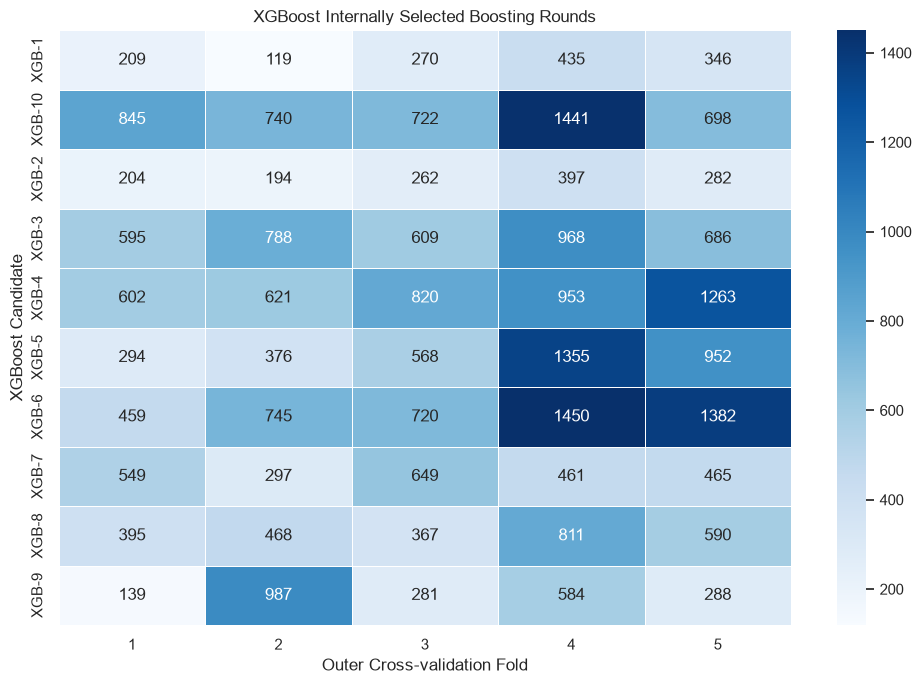

In [17]:

# Analyse XGBoost selected boosting rounds

xgb_cv_results = (
    cv_results_df.loc[
        cv_results_df["Algorithm"]
        == "XGBoost"
    ]
    .copy()
)

assert (
    xgb_cv_results[
        "selected_boosting_rounds"
    ].notna().all()
)

assert (
    xgb_cv_results[
        "selected_boosting_rounds"
    ] > 0
).all()

xgb_round_summary = (
    xgb_cv_results
    .groupby("Candidate")
    .agg(
        Minimum_Rounds=(
            "selected_boosting_rounds", "min"
        ),

        Median_Rounds=(
            "selected_boosting_rounds", "median"
        ),

        Maximum_Rounds=(
            "selected_boosting_rounds", "max"
        ),

        Mean_Rounds=(
            "selected_boosting_rounds", "mean"
        ),

        Std_Rounds=(
            "selected_boosting_rounds", "std"
        ),

        Folds_Reaching_Budget=(
            "boosting_budget_reached", "sum"
        ),
    )
)

display(
    xgb_round_summary.round(3)
)

round_matrix = (
    xgb_cv_results.pivot(
        index="Candidate",
        columns="Fold",
        values="selected_boosting_rounds",
    )
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    round_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5,
)

plt.title(
    "XGBoost Internally Selected Boosting Rounds"
)

plt.xlabel("Outer Cross-validation Fold")

plt.ylabel("XGBoost Candidate")

plt.tight_layout()
plt.show()

## 10. Cross-validation Candidate Selection

Require valid, finite predictions and zero
non-positive out-of-fold predictions.

Select the lowest mean-CV-MAE candidate
from each algorithm family.

Select the overall accuracy-leading model
using the same predefined metric.

The original validation partition is not used
to determine this ranking.

In [18]:

# Select eligible candidates

eligible_cv_summary = cv_summary.loc[
    (
        cv_summary[
            "Non_Positive_Predictions"
        ] == 0
    )
    &
    (
        cv_summary["Folds"] == N_SPLITS
    )
].copy()

assert not eligible_cv_summary.empty

family_leaders = (
    eligible_cv_summary
    .sort_values("Mean_CV_MAE")
    .groupby(
        "Algorithm",
        sort=False,
        as_index=False,
    )
    .head(1)
    .reset_index(drop=True)
)

display(
    family_leaders[
        [
            "Candidate",
            "Algorithm",
            "Mean_CV_MAE",
            "Std_CV_MAE",
            "Worst_Fold_MAE",
            "Mean_CV_RMSE",
            "Mean_CV_R2",
            "Improvement_vs_Baseline_Pct",
        ]
    ].round(6)
)

ml_eligible = eligible_cv_summary.loc[
    eligible_cv_summary["Algorithm"]
    != "Equipment Mean"
]

assert not ml_eligible.empty

accuracy_leader_row = (
    ml_eligible
    .sort_values(
        ["Mean_CV_MAE", "Std_CV_MAE", "Candidate"]
    )
    .iloc[0]
)

accuracy_leader_name = (
    accuracy_leader_row["Candidate"]
)

accuracy_leader = candidate_lookup[
    accuracy_leader_name
]

print(
    "Accuracy-leading CV candidate:",
    accuracy_leader_name
)

print(
    "Algorithm:",
    accuracy_leader["algorithm"]
)

print(
    "Mean CV MAE:",
    accuracy_leader_row["Mean_CV_MAE"]
)

print("\nSelected hyperparameters:")

print(
    json.dumps(
        accuracy_leader,
        indent=4,
    )
)

,Candidate,Algorithm,Mean_CV_MAE,Std_CV_MAE,Worst_Fold_MAE,Mean_CV_RMSE,Mean_CV_R2,Improvement_vs_Baseline_Pct
0,XGB-4,XGBoost,1.209290,0.123581,1.353097,1.609894,0.563257,38.462110
1,RF-1,Random Forest,1.274680,0.100218,1.396786,1.687085,0.519414,35.134557
2,Ridge-2,Ridge,1.313573,0.104109,1.408450,1.711619,0.499753,33.155396
3,Equipment Mean,Equipment Mean,1.965114,0.141703,2.161639,2.536734,-0.087495,0.000000


Accuracy-leading CV candidate: XGB-4
Algorithm: XGBoost
Mean CV MAE: 1.2092899217275688

Selected hyperparameters:
{
    "name": "XGB-4",
    "algorithm": "XGBoost",
    "include_equipment": false,
    "parameters": {
        "missing_strategy": "median",
        "max_depth": 4,
        "learning_rate": 0.025,
        "n_estimators": 1500,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.0,
        "random_state": 42
    }
}


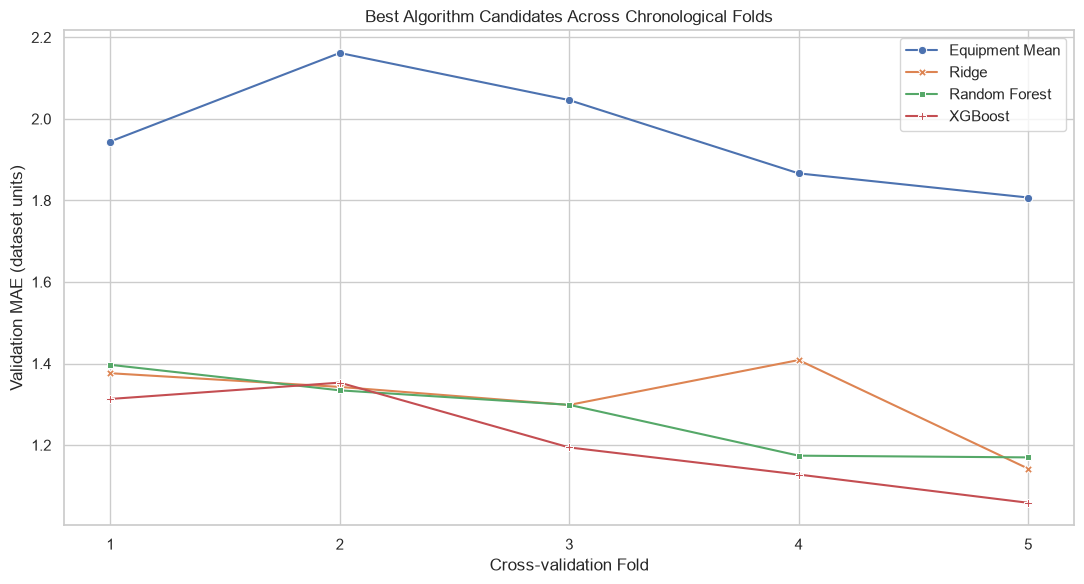

In [19]:

# Plot the best candidate from each model family

leader_names = (
    family_leaders["Candidate"]
    .tolist()
)

leader_fold_results = (
    cv_results_df.loc[
        cv_results_df["Candidate"]
        .isin(leader_names)
    ]
    .copy()
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=leader_fold_results,
    x="Fold",
    y="MAE",
    hue="Algorithm",
    style="Algorithm",
    markers=True,
    dashes=False,
    errorbar=None,
)

plt.xticks(
    range(1, N_SPLITS + 1)
)

plt.title(
    "Best Algorithm Candidates Across "
    "Chronological Folds"
)

plt.xlabel("Cross-validation Fold")

plt.ylabel("Validation MAE (dataset units)")

plt.legend()

plt.tight_layout()
plt.show()

## 11. Cross-validated Equipment Metadata Ablation

Compare matched model configurations with and
without explicit equipment identifiers.

Evaluate the incremental predictive usefulness
of equipment metadata across chronological folds.

Differences in selected XGBoost boosting rounds
may occur because each candidate undergoes its
own training-internal early-stopping procedure.

In [20]:

# Compare matched equipment configurations

equipment_pairs = [
    ("Ridge", "Ridge-2", "Ridge-1"),

    ("Random Forest", "RF-2", "RF-1"),

    ("XGBoost Shallow", "XGB-2", "XGB-1"),

    ("XGBoost Slow Median", "XGB-4", "XGB-3"),

    ("XGBoost Slow Native", "XGB-6", "XGB-5"),
]

equipment_cv_rows = []

for label, apc_only, apc_equipment in (
    equipment_pairs
):

    only_mae = float(
        cv_summary.loc[
            cv_summary["Candidate"]
            == apc_only,
            "Mean_CV_MAE",
        ].iloc[0]
    )

    equipment_mae = float(
        cv_summary.loc[
            cv_summary["Candidate"]
            == apc_equipment,
            "Mean_CV_MAE",
        ].iloc[0]
    )

    equipment_cv_rows.append({
        "Configuration": label,

        "APC Only MAE": only_mae,

        "APC + Equipment MAE": (
            equipment_mae
        ),

        "Equipment Improvement (%)": (
            calculate_mae_improvement(
                only_mae,
                equipment_mae,
            )
        ),
    })

equipment_cv_ablation = pd.DataFrame(
    equipment_cv_rows
)

display(
    equipment_cv_ablation.round(6)
)

,Configuration,APC Only MAE,APC + Equipment MAE,Equipment Improvement (%)
0,Ridge,1.313573,1.321244,-0.583987
1,Random Forest,1.277475,1.274680,0.218780
2,XGBoost Shallow,1.273792,1.245121,2.250820
3,XGBoost Slow Median,1.209290,1.214348,-0.418234
4,XGBoost Slow Native,1.213300,1.220947,-0.630220


In [21]:

# Compare median and native missing handling

missing_strategy_pairs = [
    ("APC + Equipment", "XGB-3", "XGB-5"),

    ("APC Only", "XGB-4", "XGB-6"),
]

missing_cv_rows = []

for label, median_name, native_name in (
    missing_strategy_pairs
):

    median_mae = float(
        cv_summary.loc[
            cv_summary["Candidate"]
            == median_name,
            "Mean_CV_MAE",
        ].iloc[0]
    )

    native_mae = float(
        cv_summary.loc[
            cv_summary["Candidate"]
            == native_name,
            "Mean_CV_MAE",
        ].iloc[0]
    )

    missing_cv_rows.append({
        "Configuration": label,

        "Median MAE": median_mae,

        "Native MAE": native_mae,

        "Native Improvement (%)": (
            calculate_mae_improvement(
                median_mae,
                native_mae,
            )
        ),
    })

missing_cv_ablation = pd.DataFrame(
    missing_cv_rows
)

display(
    missing_cv_ablation.round(6)
)

,Configuration,Median MAE,Native MAE,Native Improvement (%)
0,APC + Equipment,1.214348,1.220947,-0.543438
1,APC Only,1.209290,1.213300,-0.331635


## 12. Deployment-Oriented Candidate Benchmarking

Refit candidate models using the eligible
historical training population.

For XGBoost, select a fixed boosting-round count
using the median of the five internally selected
cross-validation round counts.

Measure:

- Estimated serialized pipeline size.
- Repeated single-record inference latency.
- Repeated batch inference latency.
- Model fitting time.

Use only historical training inputs for
computational benchmarking.

Select a compact candidate within 1% of the
accuracy-leading mean CV MAE.

These measurements represent local CPU execution,
not production API latency or runtime memory usage.

In [22]:

# Define the deployment benchmarking shortlist

COMPACT_MAE_TOLERANCE = 0.01

accuracy_leader_mae = float(
    accuracy_leader_row["Mean_CV_MAE"]
)

compact_mae_limit = (
    accuracy_leader_mae
    * (1 + COMPACT_MAE_TOLERANCE)
)

near_best_names = (
    ml_eligible.loc[
        ml_eligible["Mean_CV_MAE"]
        <= compact_mae_limit,
        "Candidate",
    ]
    .tolist()
)

# Include the best model from every family
# and every eligible model within the tolerance.

benchmark_names = list(
    dict.fromkeys(
        leader_names + near_best_names
    )
)

print(
    "Accuracy-leading CV MAE:",
    accuracy_leader_mae
)

print(
    "Maximum MAE for compact candidate:",
    compact_mae_limit
)

print(
    "\nNear-best candidates:",
    near_best_names
)

print(
    "\nDeployment benchmarking shortlist:",
    benchmark_names
)

Accuracy-leading CV MAE: 1.2092899217275688
Maximum MAE for compact candidate: 1.2213828209448445

Near-best candidates: ['XGB-4', 'XGB-10', 'XGB-6', 'XGB-3', 'XGB-9', 'XGB-5']

Deployment benchmarking shortlist: ['XGB-4', 'RF-1', 'Ridge-2', 'Equipment Mean', 'XGB-10', 'XGB-6', 'XGB-3', 'XGB-9', 'XGB-5']


In [23]:

# Convert fold-specific rounds into fixed configurations

fixed_round_lookup = {}

for candidate_name in benchmark_names:

    candidate = candidate_lookup[
        candidate_name
    ]

    if candidate["algorithm"] == "XGBoost":

        selected_rounds = (
            xgb_cv_results.loc[
                xgb_cv_results["Candidate"]
                == candidate_name,
                "selected_boosting_rounds",
            ]
            .to_numpy(dtype=float)
        )

        assert len(
            selected_rounds
        ) == N_SPLITS

        fixed_round_lookup[
            candidate_name
        ] = int(
            np.median(selected_rounds)
        )

    else:

        fixed_round_lookup[
            candidate_name
        ] = None

display(
    pd.DataFrame([
        {
            "Candidate": name,
            "Fixed Boosting Rounds": rounds,
        }

        for name, rounds
        in fixed_round_lookup.items()
    ])
)

,Candidate,Fixed Boosting Rounds
0,XGB-4,820.0
1,RF-1,NaN
2,Ridge-2,NaN
3,Equipment Mean,NaN
4,XGB-10,740.0
5,XGB-6,745.0
6,XGB-3,686.0
7,XGB-9,288.0
8,XGB-5,568.0


In [24]:

# Reusable repeated inference timing function

def measure_prediction_latency(
    model,
    inputs,
    repetitions=20,
    warmup=3,
):

    for _ in range(warmup):

        model.predict(inputs)

    elapsed_ms = []

    for _ in range(repetitions):

        start = time.perf_counter()

        model.predict(inputs)

        elapsed_ms.append(
            (
                time.perf_counter()
                - start
            ) * 1000
        )

    return {
        "median_ms": float(
            np.median(elapsed_ms)
        ),

        "p95_ms": float(
            np.quantile(elapsed_ms, 0.95)
        ),

        "minimum_ms": float(
            np.min(elapsed_ms)
        ),
    }


print("Inference benchmarking function ready.")

Inference benchmarking function ready.


In [25]:

# Benchmark shortlisted fitted models

import platform
import os

benchmark_models = {}

deployment_rows = []

benchmark_batch = (
    assessment_train_df
    .sample(
        n=min(
            256,
            len(assessment_train_df),
        ),
        random_state=RANDOM_STATE,
    )
    .copy()
)

for name in benchmark_names:

    candidate = candidate_lookup[name]

    columns = get_candidate_columns(
        candidate,
        apc_features,
    )

    start = time.perf_counter()

    fitted_model, fit_info = fit_candidate_model(
        candidate=candidate,

        training_data=assessment_train_df,

        apc_features=apc_features,

        target=TARGET,

        n_jobs=N_JOBS,

        fixed_boosting_rounds=(
            fixed_round_lookup[name]
        ),
    )

    fit_seconds = (
        time.perf_counter() - start
    )

    serialized_bytes = len(
        pickle.dumps(
            fitted_model,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    )

    single_latency = (
        measure_prediction_latency(
            fitted_model,
            benchmark_batch[columns].iloc[[0]],
            repetitions=30,
        )
    )

    batch_latency = (
        measure_prediction_latency(
            fitted_model,
            benchmark_batch[columns],
            repetitions=20,
        )
    )

    benchmark_models[name] = fitted_model

    deployment_rows.append({
        "Candidate": name,

        "Algorithm": candidate["algorithm"],

        "Fixed Boosting Rounds": (
            fixed_round_lookup[name]
        ),

        "Serialized Size (Bytes)": (
            serialized_bytes
        ),

        "Serialized Size (MiB)": (
            serialized_bytes / 1024**2
        ),

        "Training Time (s)": fit_seconds,

        "Single Median Latency (ms)": (
            single_latency["median_ms"]
        ),

        "Single P95 Latency (ms)": (
            single_latency["p95_ms"]
        ),

        "Batch Median Latency (ms)": (
            batch_latency["median_ms"]
        ),

        "Batch P95 Latency (ms)": (
            batch_latency["p95_ms"]
        ),

        "Batch Records": len(benchmark_batch),
    })

    print(
        f"{name}: "
        f"{serialized_bytes / 1024**2:.4f} MiB"
    )

deployment_benchmark_df = (
    pd.DataFrame(deployment_rows)
    .merge(
        cv_summary[
            [
                "Candidate",
                "Mean_CV_MAE",
                "Std_CV_MAE",
            ]
        ],
        on="Candidate",
        validate="one_to_one",
    )
)

display(
    deployment_benchmark_df
    .sort_values("Mean_CV_MAE")
    .round(6)
)

benchmark_environment = {
    "platform": platform.platform(),
    "processor": platform.processor(),
    "logical_cpu_count": os.cpu_count(),
    "n_jobs": N_JOBS,
    "single_record_repetitions": 30,
    "batch_repetitions": 20,
    "warmup_repetitions": 3,
    "batch_records": len(benchmark_batch),
}

print("\nBenchmark environment:")

print(
    json.dumps(
        benchmark_environment,
        indent=4,
    )
)

XGB-4: 1.2530 MiB
RF-1: 57.8245 MiB
Ridge-2: 0.0112 MiB
Equipment Mean: 0.0005 MiB
XGB-10: 1.0997 MiB
XGB-6: 1.1357 MiB
XGB-3: 1.0515 MiB
XGB-9: 0.6430 MiB
XGB-5: 0.8694 MiB


,Candidate,Algorithm,Fixed Boosting Rounds,Serialized Size (Bytes),Serialized Size (MiB),Training Time (s),Single Median Latency (ms),Single P95 Latency (ms),Batch Median Latency (ms),Batch P95 Latency (ms),Batch Records,Mean_CV_MAE,Std_CV_MAE
0,XGB-4,XGBoost,820.0,1313817,1.252954,2.508611,5.62290,6.451785,6.88760,7.843290,256,1.209290,0.123581
4,XGB-10,XGBoost,740.0,1153156,1.099735,2.278786,7.22730,8.113905,10.56760,11.975470,256,1.213018,0.118511
5,XGB-6,XGBoost,745.0,1190911,1.135741,2.526801,3.34930,3.971360,5.63600,6.502345,256,1.213300,0.116075
6,XGB-3,XGBoost,686.0,1102573,1.051496,2.563135,10.86545,14.761250,11.26595,11.855875,256,1.214348,0.123586
7,XGB-9,XGBoost,288.0,674268,0.643032,1.515928,7.04365,8.133350,8.67655,9.652695,256,1.214356,0.134130
8,XGB-5,XGBoost,568.0,911670,0.869436,1.741234,6.15850,7.593045,7.61135,8.632160,256,1.220947,0.138510
1,RF-1,Random Forest,NaN,60633398,57.824514,3.104052,49.22590,92.266690,58.67355,79.751160,256,1.274680,0.100218
2,Ridge-2,Ridge,NaN,11722,0.011179,0.111099,2.34765,2.696340,3.45775,5.451440,256,1.313573,0.104109
3,Equipment Mean,Equipment Mean,NaN,515,0.000491,0.001790,0.20980,0.226320,0.24965,0.296515,256,1.965114,0.141703



Benchmark environment:
{
    "platform": "Windows-11-10.0.26300-SP0",
    "processor": "AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD",
    "logical_cpu_count": 16,
    "n_jobs": -1,
    "single_record_repetitions": 30,
    "batch_repetitions": 20,
    "warmup_repetitions": 3,
    "batch_records": 256
}


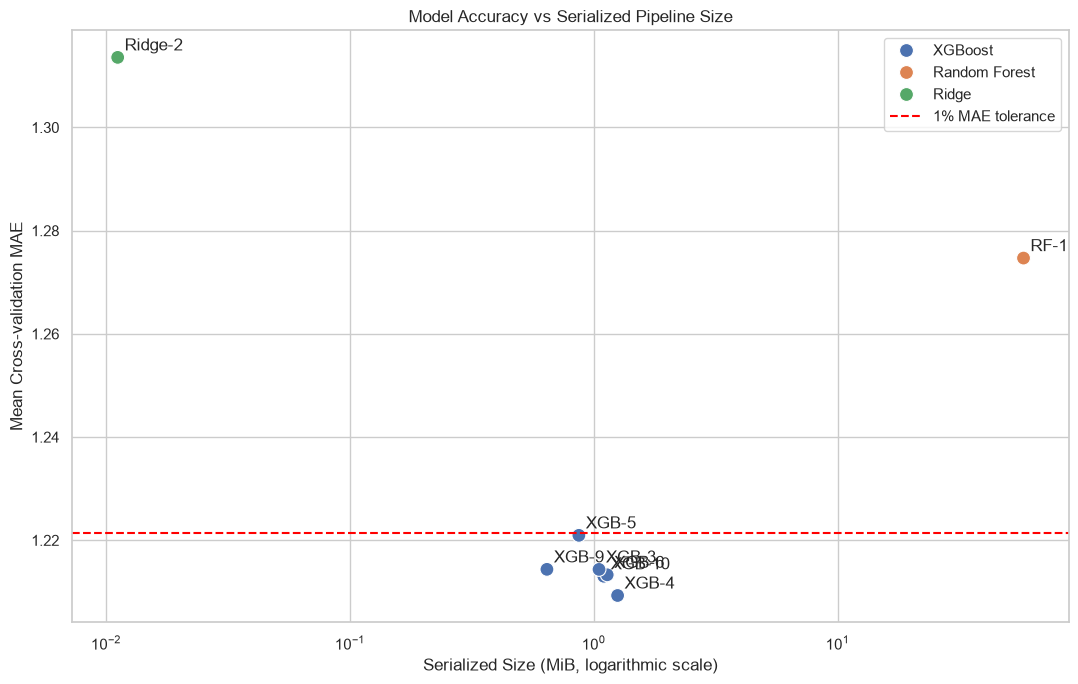

In [26]:

# Visualise accuracy-complexity trade-offs

deployment_plot_df = (
    deployment_benchmark_df.loc[
        deployment_benchmark_df["Algorithm"]
        != "Equipment Mean"
    ]
    .copy()
)

plt.figure(figsize=(11, 7))

ax = sns.scatterplot(
    data=deployment_plot_df,

    x="Serialized Size (MiB)",

    y="Mean_CV_MAE",

    hue="Algorithm",

    s=100,
)

for _, row in deployment_plot_df.iterrows():

    ax.annotate(
        row["Candidate"],

        (
            row["Serialized Size (MiB)"],
            row["Mean_CV_MAE"],
        ),

        xytext=(5, 5),

        textcoords="offset points",
    )

ax.axhline(
    compact_mae_limit,
    color="red",
    linestyle="--",
    label="1% MAE tolerance",
)

ax.set_xscale("log")

plt.title(
    "Model Accuracy vs Serialized Pipeline Size"
)

plt.xlabel(
    "Serialized Size (MiB, logarithmic scale)"
)

plt.ylabel("Mean Cross-validation MAE")

plt.legend()

plt.tight_layout()
plt.show()


## 13. Final Candidate Selection Policy

Select the accuracy-leading ML candidate using
mean chronological cross-validation MAE.

Identify the smallest serialized ML candidate
within the predefined 1% MAE tolerance.

Use the accuracy-leading candidate as the
default thickness virtual metrology model.

Preserve the compact candidate as a deployment
alternative.

Freeze hyperparameters and boosting rounds
before examining original-validation predictions.

Do not modify the configuration based on final
held-out test performance.

In [27]:

# Select the compact deployment candidate

compact_eligible = (
    deployment_benchmark_df.loc[
        deployment_benchmark_df["Candidate"]
        .isin(near_best_names)
    ]
    .sort_values(
        [
            "Serialized Size (Bytes)",
            "Mean_CV_MAE",
            "Candidate",
        ]
    )
)

assert not compact_eligible.empty

compact_row = compact_eligible.iloc[0]

compact_candidate_name = (
    compact_row["Candidate"]
)

accuracy_benchmark_row = (
    deployment_benchmark_df.loc[
        deployment_benchmark_df["Candidate"]
        == accuracy_leader_name
    ].iloc[0]
)

size_reduction_pct = (
    1
    - compact_row["Serialized Size (Bytes)"]
    / accuracy_benchmark_row[
        "Serialized Size (Bytes)"
    ]
) * 100

mae_increase_pct = (
    compact_row["Mean_CV_MAE"]
    / accuracy_leader_mae
    - 1
) * 100


def freeze_candidate(
    name,
    candidate_lookup,
    fixed_round_lookup,
):

    configuration = candidate_lookup[name]

    frozen = {
        "name": configuration["name"],

        "algorithm": configuration[
            "algorithm"
        ],

        "include_equipment": configuration[
            "include_equipment"
        ],

        "parameters": configuration[
            "parameters"
        ].copy(),
    }

    if frozen["algorithm"] == "XGBoost":

        frozen["parameters"][
            "n_estimators"
        ] = int(
            fixed_round_lookup[name]
        )

    return frozen


selected_candidate = freeze_candidate(
    accuracy_leader_name,
    candidate_lookup,
    fixed_round_lookup,
)

compact_candidate = freeze_candidate(
    compact_candidate_name,
    candidate_lookup,
    fixed_round_lookup,
)

print(
    "Selected thickness model:",
    selected_candidate["name"]
)

print(
    "Compact alternative:",
    compact_candidate["name"]
)

print(
    f"Compact candidate MAE increase: "
    f"{mae_increase_pct:.6f}%"
)

print(
    f"Compact candidate size reduction: "
    f"{size_reduction_pct:.6f}%"
)

print("\nFrozen thickness configuration:")

print(
    json.dumps(
        selected_candidate,
        indent=4,
    )
)

Selected thickness model: XGB-4
Compact alternative: XGB-9
Compact candidate MAE increase: 0.418965%
Compact candidate size reduction: 48.678697%

Frozen thickness configuration:
{
    "name": "XGB-4",
    "algorithm": "XGBoost",
    "include_equipment": false,
    "parameters": {
        "missing_strategy": "median",
        "max_depth": 4,
        "learning_rate": 0.025,
        "n_estimators": 820,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.0,
        "random_state": 42
    }
}


In [28]:

# Preserve the pre-assessment model selection

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

selection_path = (
    results_dir
    / "thickness_model_selection.json"
)

selection_record = {
    "project": "STRATUM",

    "target": TARGET,

    "dataset_sha256": current_sha256,

    "selection_partition": (
        "original_training_chronological_cv"
    ),

    "primary_metric": "Mean CV MAE",

    "selection_policy": (
        "Minimum eligible mean chronological CV MAE"
    ),

    "compact_mae_tolerance": (
        COMPACT_MAE_TOLERANCE
    ),

    "boosting_round_policy": (
        "Median internally selected CV boosting rounds"
    ),

    "selected_candidate": selected_candidate,

    "compact_candidate": compact_candidate,

    "selected_mean_cv_mae": (
        accuracy_leader_mae
    ),

    "selected_std_cv_mae": float(
        accuracy_leader_row["Std_CV_MAE"]
    ),

    "compact_mean_cv_mae": float(
        compact_row["Mean_CV_MAE"]
    ),

    "compact_mae_increase_pct": float(
        mae_increase_pct
    ),

    "compact_size_reduction_pct": float(
        size_reduction_pct
    ),

    "baseline_mean_cv_mae": baseline_cv_mae,

    "cv_folds": N_SPLITS,
}

selection_path.write_text(
    json.dumps(
        selection_record,
        indent=4,
        allow_nan=False,
    ),
    encoding="utf-8",
)

print(
    "Frozen model configuration saved:"
)

print(
    "ml/results/thickness_model_selection.json"
)

Frozen model configuration saved:
ml/results/thickness_model_selection.json


## 14. Post-Selection Original-Validation Assessment

Evaluate shortlisted fitted candidates on the
original chronological validation partition.

Model selection was completed before this
assessment using training-internal CV results.

Compare predictive performance, bias, error
percentiles and physical plausibility.

The original validation partition has previously
informed model development and is not an
independent final test set.

Final held-out targets remain reserved.

In [29]:

# Evaluate shortlisted models on original validation

assessment_rows = []

assessment_predictions = {}

y_val = val_df[TARGET].to_numpy()

assert np.isfinite(y_val).all()
assert (y_val > 0).all()

for name, model in benchmark_models.items():

    candidate = candidate_lookup[name]

    columns = get_candidate_columns(
        candidate,
        apc_features,
    )

    predictions = np.asarray(
        model.predict(
            val_df[columns]
        )
    )

    assert predictions.shape == y_val.shape

    assert np.isfinite(predictions).all()

    metrics = evaluate_regression(
        y_val,
        predictions,
    )

    absolute_errors = np.abs(
        y_val - predictions
    )

    assessment_rows.append({
        "Candidate": name,

        "Algorithm": candidate["algorithm"],

        "Validation Records": len(y_val),

        **metrics,

        "P95 Absolute Error": float(
            np.quantile(
                absolute_errors,
                0.95,
            )
        ),

        "Maximum Absolute Error": float(
            absolute_errors.max()
        ),

        "Non-Positive Predictions": int(
            (predictions <= 0).sum()
        ),

        "Outside Training Target Range": int(
            (
                (
                    predictions
                    < assessment_train_df[
                        TARGET
                    ].min()
                )
                |
                (
                    predictions
                    > assessment_train_df[
                        TARGET
                    ].max()
                )
            ).sum()
        ),
    })

    assessment_predictions[name] = (
        predictions
    )

assessment_results_df = (
    pd.DataFrame(assessment_rows)
    .merge(
        cv_summary[
            [
                "Candidate",
                "Mean_CV_MAE",
                "Std_CV_MAE",
            ]
        ],
        on="Candidate",
        validate="one_to_one",
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    assessment_results_df.round(6)
)

selected_assessment = (
    assessment_results_df.loc[
        assessment_results_df["Candidate"]
        == selected_candidate["name"]
    ].iloc[0]
)

assert (
    selected_assessment[
        "Non-Positive Predictions"
    ] == 0
), "Selected model failed positivity assessment."

selected_predictions = (
    assessment_predictions[
        selected_candidate["name"]
    ]
)

print(
    "Frozen thickness-model configuration:",
    selected_candidate["name"]
)

print(
    "Cross-validation MAE:",
    accuracy_leader_mae
)

print(
    "Original-validation MAE:",
    selected_assessment["MAE"]
)

print(
    "Original-validation RMSE:",
    selected_assessment["RMSE"]
)

print(
    "Original-validation R2:",
    selected_assessment["R2"]
)

,Candidate,Algorithm,Validation Records,MAE,RMSE,R2,MAPE (%),Bias,P95 Absolute Error,Maximum Absolute Error,Non-Positive Predictions,Outside Training Target Range,Mean_CV_MAE,Std_CV_MAE
0,XGB-9,XGBoost,834,1.064292,1.429050,0.657666,0.700844,-0.035274,3.031605,5.789035,0,0,1.214356,0.134130
1,XGB-10,XGBoost,834,1.067970,1.450613,0.647257,0.703309,-0.042409,3.028025,6.035022,0,0,1.213018,0.118511
2,XGB-3,XGBoost,834,1.071739,1.448077,0.648490,0.705790,-0.039744,3.084007,5.953067,0,0,1.214348,0.123586
3,XGB-4,XGBoost,834,1.072550,1.443448,0.650733,0.706370,-0.058045,3.025310,5.821262,0,0,1.209290,0.123581
4,XGB-6,XGBoost,834,1.089166,1.460500,0.642432,0.717076,-0.067998,2.988277,6.508060,0,0,1.213300,0.116075
5,XGB-5,XGBoost,834,1.089226,1.463487,0.640968,0.717248,-0.042832,3.015396,6.475696,0,0,1.220947,0.138510
6,RF-1,Random Forest,834,1.158247,1.529514,0.607841,0.763190,0.028238,3.057793,6.312538,0,0,1.274680,0.100218
7,Ridge-2,Ridge,834,1.303125,1.691001,0.520661,0.858197,-0.086822,3.386266,9.573044,0,0,1.313573,0.104109
8,Equipment Mean,Equipment Mean,834,1.995479,2.444380,-0.001596,1.320842,0.664447,4.632090,7.557241,0,0,1.965114,0.141703


Frozen thickness-model configuration: XGB-4
Cross-validation MAE: 1.2092899217275688
Original-validation MAE: 1.0725497318716912
Original-validation RMSE: 1.443447515229237
Original-validation R2: 0.6507334197249336


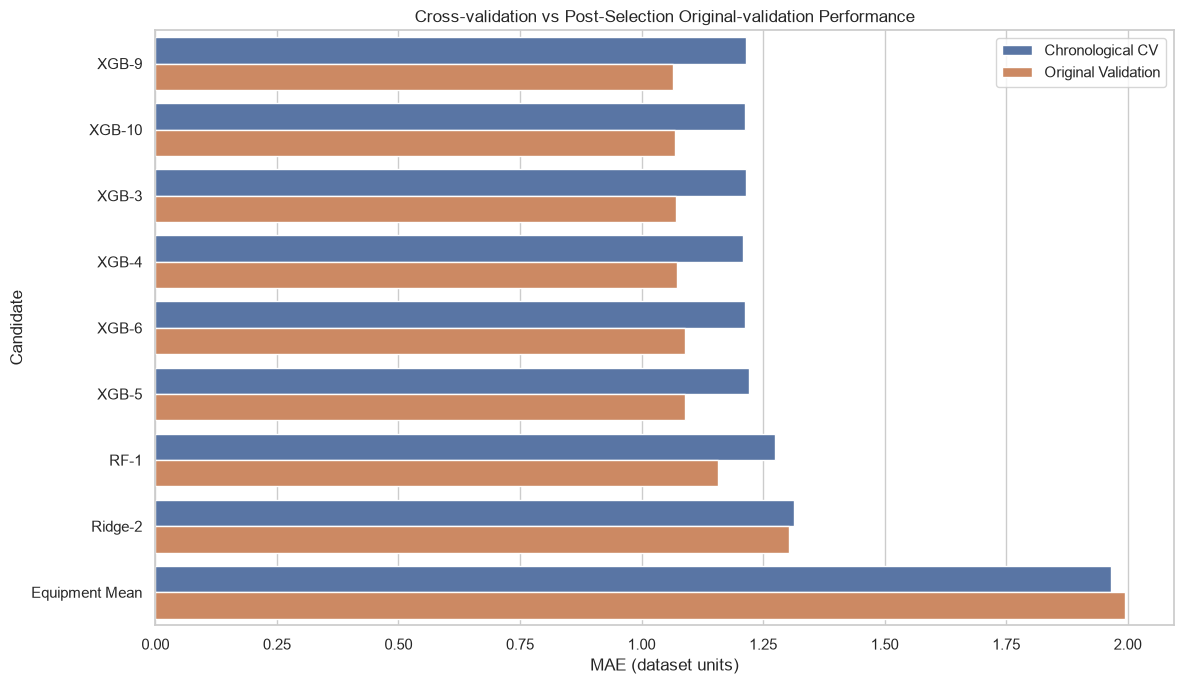

In [30]:

# Compare cross-validation and later validation MAE

assessment_plot_data = (
    assessment_results_df.melt(
        id_vars=["Candidate"],

        value_vars=[
            "Mean_CV_MAE",
            "MAE",
        ],

        var_name="Evaluation",

        value_name="Mean Absolute Error",
    )
)

assessment_plot_data["Evaluation"] = (
    assessment_plot_data["Evaluation"]
    .map({
        "Mean_CV_MAE": "Chronological CV",
        "MAE": "Original Validation",
    })
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=assessment_plot_data,

    x="Mean Absolute Error",

    y="Candidate",

    hue="Evaluation",
)

plt.title(
    "Cross-validation vs Post-Selection "
    "Original-validation Performance"
)

plt.xlabel("MAE (dataset units)")

plt.ylabel("Candidate")

plt.legend()

plt.tight_layout()
plt.show()

In [31]:

# Compare the optimised candidate with previous results

selected_validation_mae = float(
    selected_assessment["MAE"]
)

assessment_baseline_mae = float(
    assessment_results_df.loc[
        assessment_results_df["Candidate"]
        == "Equipment Mean",
        "MAE",
    ].iloc[0]
)

historical_comparison = pd.DataFrame([
    {
        "Model": "Previous Equipment Mean",
        "Validation MAE": baseline_reference_mae,
    },
    {
        "Model": "Previous Bounded Ridge",
        "Validation MAE": ridge_reference_mae,
    },
    {
        "Model": "Previous Random Forest",
        "Validation MAE": forest_reference_mae,
    },
    {
        "Model": "Previous XGBoost",
        "Validation MAE": xgb_reference_mae,
    },
    {
        "Model": "CV-Selected Thickness Model",
        "Validation MAE": selected_validation_mae,
    },
])

display(
    historical_comparison.round(6)
)

print(
    "Improvement vs matched assessment baseline:",
    calculate_mae_improvement(
        assessment_baseline_mae,
        selected_validation_mae,
    ),
    "%"
)

if (
    assessment_purge_info["purged_records"]
    == 0
):

    print(
        "Improvement vs previous XGBoost:",
        calculate_mae_improvement(
            xgb_reference_mae,
            selected_validation_mae,
        ),
        "%"
    )

else:

    print(
        "Historical comparison limitation: "
        "training populations differ because "
        "of batch or timestamp purging."
    )

,Model,Validation MAE
0,Previous Equipment Mean,1.995479
1,Previous Bounded Ridge,1.267788
2,Previous Random Forest,1.158247
3,Previous XGBoost,1.079062
4,CV-Selected Thickness Model,1.072550


Improvement vs matched assessment baseline: 46.25100336946666 %
Improvement vs previous XGBoost: 0.6035461934655855 %


## 15. Selected-Model Prediction Diagnostics

Evaluate actual versus predicted thickness
and residual distributions for the frozen
thickness candidate.

Inspect physical plausibility, systematic bias,
and prediction behaviour at extreme target values.

These observations provide development-stage
diagnostics rather than independent test evidence.

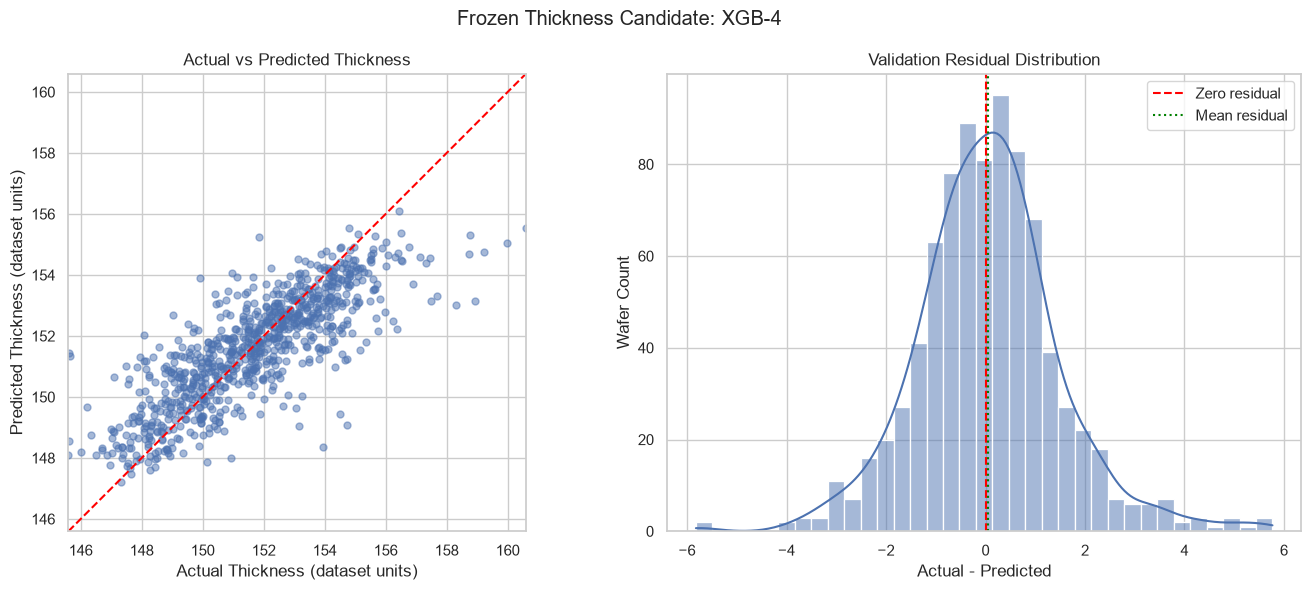

In [32]:

# Actual vs predicted and residual distribution

residuals = (
    y_val - selected_predictions
)

lower = min(
    y_val.min(),
    selected_predictions.min(),
)

upper = max(
    y_val.max(),
    selected_predictions.max(),
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
)

axes[0].scatter(
    y_val,
    selected_predictions,
    alpha=0.5,
    s=25,
)

axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
)

axes[0].set_xlim(lower, upper)
axes[0].set_ylim(lower, upper)

axes[0].set_aspect(
    "equal",
    adjustable="box",
)

axes[0].set_title(
    "Actual vs Predicted Thickness"
)

axes[0].set_xlabel(
    "Actual Thickness (dataset units)"
)

axes[0].set_ylabel(
    "Predicted Thickness (dataset units)"
)

sns.histplot(
    residuals,
    bins=35,
    kde=True,
    ax=axes[1],
)

axes[1].axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero residual",
)

axes[1].axvline(
    residuals.mean(),
    color="green",
    linestyle=":",
    label="Mean residual",
)

axes[1].set_title(
    "Validation Residual Distribution"
)

axes[1].set_xlabel(
    "Actual - Predicted"
)

axes[1].set_ylabel(
    "Wafer Count"
)

axes[1].legend()

fig.suptitle(
    f"Frozen Thickness Candidate: "
    f"{selected_candidate['name']}"
)

plt.tight_layout()
plt.show()

In [33]:

# Selected model equipment-level diagnostics

selected_error_df = pd.DataFrame({
    "equipment": val_df[
        "equipment"
    ].to_numpy(),

    "Actual": y_val,

    "Predicted": selected_predictions,
})

selected_error_df["Bias"] = (
    selected_error_df["Predicted"]
    - selected_error_df["Actual"]
)

selected_error_df["Absolute Error"] = (
    selected_error_df["Bias"].abs()
)

selected_error_df["Squared Error"] = (
    selected_error_df["Bias"] ** 2
)

equipment_summary = (
    selected_error_df
    .groupby("equipment")
    .agg(
        Records=("Actual", "count"),

        MAE=("Absolute Error", "mean"),

        MSE=("Squared Error", "mean"),

        Bias=("Bias", "mean"),

        Maximum_Error=(
            "Absolute Error", "max"
        ),
    )
)

equipment_summary["RMSE"] = np.sqrt(
    equipment_summary.pop("MSE")
)

equipment_summary = (
    equipment_summary
    .sort_values(
        "MAE",
        ascending=False,
    )
)

display(
    equipment_summary.round(6)
)

if "equipment_16" in equipment_summary.index:

    print(
        "\nPreviously problematic equipment_16:"
    )

    display(
        equipment_summary.loc[
            ["equipment_16"]
        ].round(6)
    )

,Records,MAE,Bias,Maximum_Error,RMSE
equipment,,,,,
equipment_16,47,1.701980,1.701980,3.552229,1.920819
equipment_11,50,1.502292,0.226903,5.685392,2.059571
equipment_1,56,1.482238,-1.281360,3.463860,1.716992
equipment_13,54,1.355406,1.162973,3.090318,1.593083
equipment_3,47,1.307721,-0.719746,5.768161,1.894699
equipment_14,56,1.304876,-0.947666,4.048241,1.577073
equipment_7,48,1.103973,-0.240757,4.329148,1.464221
equipment_8,54,1.047144,0.112280,2.963598,1.311850
equipment_15,50,0.990818,-0.221807,4.397226,1.343306



Previously problematic equipment_16:


,Records,MAE,Bias,Maximum_Error,RMSE
equipment,,,,,
equipment_16,47,1.70198,1.70198,3.552229,1.920819


## 16. Model Optimisation Integrity Verification

Verify the completeness of candidate-fold results,
aligned out-of-fold observations, chronological
separation, boosting-round validity, and frozen
candidate selection.

These checks establish implementation integrity.

They do not establish statistical independence
between chronological folds.

In [34]:

# Verify candidate and fold completeness

assert len(cv_results_df) == 95

assert cv_results_df[
    ["Candidate", "Fold"]
].duplicated().sum() == 0

assert len(cv_summary) == 19

assert (
    cv_summary["Folds"] == 5
).all()

assert np.isfinite(
    cv_results_df[
        ["MAE", "RMSE", "R2", "Bias"]
    ].to_numpy()
).all()

expected_oof_count = (
    len(candidates)
    * len(all_cv_validation_ids)
)

assert len(
    oof_predictions_df
) == expected_oof_count

assert (
    oof_predictions_df[
        ["Candidate", "wafer_id"]
    ].duplicated().sum() == 0
)

reference_oof_ids = set(
    all_cv_validation_ids
)

for name, group in (
    oof_predictions_df.groupby("Candidate")
):

    assert set(
        group["wafer_id"]
    ) == reference_oof_ids

    assert np.isfinite(
        group["Predicted"]
    ).all()


# Verify XGBoost round selection

for _, row in xgb_cv_results.iterrows():

    candidate = candidate_lookup[
        row["Candidate"]
    ]

    budget = candidate["parameters"][
        "n_estimators"
    ]

    selected_rounds = row[
        "selected_boosting_rounds"
    ]

    assert (
        1 <= selected_rounds <= budget
    )


# Verify frozen selection

saved_selection = json.loads(
    selection_path.read_text(
        encoding="utf-8"
    )
)

assert (
    saved_selection["selected_candidate"]
    == selected_candidate
)

assert (
    saved_selection["dataset_sha256"]
    == current_sha256
)

assert (
    compact_row["Mean_CV_MAE"]
    <= compact_mae_limit + 1e-12
)

assert (
    selected_candidate["name"]
    == accuracy_leader_name
)

print("Cross-validation integrity: PASSED")

print(
    "Verified candidate-fold evaluations:",
    len(cv_results_df)
)

print(
    "Verified out-of-fold predictions:",
    len(oof_predictions_df)
)

print(
    "Frozen model selection: VERIFIED"
)

print(
    "Reserved final test targets not evaluated."
)

Cross-validation integrity: PASSED
Verified candidate-fold evaluations: 95
Verified out-of-fold predictions: 37905
Frozen model selection: VERIFIED
Reserved final test targets not evaluated.


## 17. Experiment Result Preservation

Preserve all candidate configurations, fold-level
metrics, cross-validation summaries, early-stopping
diagnostics, and model-selection decisions.

Record computational benchmarking results and
post-selection validation performance.

Preserve floating-point precision and use
JSON null for unavailable numerical values.

Do not export individual wafer observations
or fitted model artifacts in this notebook.

In [35]:

# Preserve experiment results

def dataframe_to_json_records(frame):

    return (
        frame.astype(object)
        .where(pd.notna(frame), None)
        .to_dict(orient="records")
    )


def json_default(value):

    if isinstance(value, np.generic):

        return value.item()

    if isinstance(value, pd.Timestamp):

        return value.isoformat()

    raise TypeError(
        f"Unsupported JSON type: "
        f"{type(value).__name__}"
    )


optimisation_results = {
    "project": "STRATUM",

    "experiment": "thickness_optimisation",

    "target": TARGET,

    "dataset_sha256": current_sha256,

    "selection_partition": (
        "original_training_chronological_cv"
    ),

    "assessment_partition": (
        "original_validation"
    ),

    "training_records": len(train_df),

    "assessment_training_records": len(
        assessment_train_df
    ),

    "validation_records": len(val_df),

    "cv_method": (
        "Chronological expanding-window "
        "cross-validation with lot and batch purging"
    ),

    "cv_folds": N_SPLITS,

    "initial_train_fraction": (
        INITIAL_TRAIN_FRACTION
    ),

    "inner_validation_fraction": (
        INNER_VALIDATION_FRACTION
    ),

    "early_stopping_rounds": (
        EARLY_STOPPING_ROUNDS
    ),

    "random_state": RANDOM_STATE,

    "n_jobs": N_JOBS,

    "sklearn_version": sklearn.__version__,

    "xgboost_version": xgboost.__version__,

    "primary_metric": "Mean CV MAE",

    "candidate_count": len(candidates),

    "completed_fold_evaluations": len(
        cv_results_df
    ),

    "oof_records_per_candidate": len(
        all_cv_validation_ids
    ),

    "search_elapsed_seconds": float(
        search_elapsed
    ),

    "baseline_mean_cv_mae": (
        baseline_cv_mae
    ),

    "candidates": candidates,

    "original_partition_overlap": (
        dataframe_to_json_records(
            partition_overlap_df
        )
    ),

    "assessment_purge_info": (
        assessment_purge_info
    ),

    "fold_summary": (
        dataframe_to_json_records(
            fold_summary_df
        )
    ),

    "inner_fold_summary": (
        dataframe_to_json_records(
            inner_fold_summary
        )
    ),

    "fold_results": (
        dataframe_to_json_records(
            cv_results_df
        )
    ),

    "cv_summary": (
        dataframe_to_json_records(
            cv_summary
        )
    ),

    "pooled_oof_metrics": (
        dataframe_to_json_records(
            pooled_metrics_df
        )
    ),

    "baseline_improvement_summary": (
        dataframe_to_json_records(
            fold_improvement_summary
            .reset_index()
        )
    ),

    "xgboost_round_summary": (
        dataframe_to_json_records(
            xgb_round_summary
            .reset_index()
        )
    ),

    "family_leaders": (
        dataframe_to_json_records(
            family_leaders
        )
    ),

    "equipment_ablation": (
        dataframe_to_json_records(
            equipment_cv_ablation
        )
    ),

    "missing_strategy_ablation": (
        dataframe_to_json_records(
            missing_cv_ablation
        )
    ),

    "deployment_benchmarks": (
        dataframe_to_json_records(
            deployment_benchmark_df
        )
    ),

    "benchmark_environment": (
        benchmark_environment
    ),

    "selection": selection_record,

    "selected_candidate": (
        selected_candidate
    ),

    "compact_candidate": (
        compact_candidate
    ),

    "selected_mean_cv_mae": (
        accuracy_leader_mae
    ),

    "selected_validation_mae": float(
        selected_assessment["MAE"]
    ),

    "selected_validation_rmse": float(
        selected_assessment["RMSE"]
    ),

    "selected_validation_r2": float(
        selected_assessment["R2"]
    ),

    "assessment_results": (
        dataframe_to_json_records(
            assessment_results_df
        )
    ),

    "equipment_error_summary": (
        dataframe_to_json_records(
            equipment_summary.reset_index()
        )
    ),

    "limitations": [
        "Search space informed by earlier "
        "model-development experiments.",

        "CV estimates used for model selection.",

        "Expanding-window folds are not independent.",

        "Fixed boosting rounds derived from the median "
        "of training-internal selected rounds.",

        "Original validation partition previously "
        "informed model development.",

        "Local latency does not represent "
        "production API latency.",

        "Potential temporal and equipment-related "
        "distribution shifts remain.",

        "Official engineering acceptance thresholds "
        "are unavailable.",

        "Final held-out test targets not evaluated.",
    ],
}

optimisation_path = (
    results_dir
    / "thickness_optimisation.json"
)

with open(
    optimisation_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        optimisation_results,
        file,
        indent=4,
        allow_nan=False,
        default=json_default,
    )

saved_optimisation = json.loads(
    optimisation_path.read_text(
        encoding="utf-8"
    )
)

assert (
    saved_optimisation["candidate_count"]
    == 19
)

assert (
    saved_optimisation[
        "completed_fold_evaluations"
    ] == 95
)

assert (
    saved_optimisation[
        "selected_candidate"
    ] == selected_candidate
)

assert (
    saved_optimisation["dataset_sha256"]
    == current_sha256
)

print("Optimisation results saved.")

print(
    "ml/results/thickness_optimisation.json"
)

print("\nExperiment JSON verification: PASSED")

Optimisation results saved.
ml/results/thickness_optimisation.json

Experiment JSON verification: PASSED


## 18. Final Optimisation Results Summary

Generate a consolidated numerical summary of
cross-validation performance, selected
hyperparameters, original-validation results,
and deployment trade-offs.

In [36]:

# Generate final research summary

print("=" * 65)
print("STRATUM - THICKNESS MODEL OPTIMISATION")
print("=" * 65)

print("\nEXPERIMENT DESIGN")

print("Candidates:", len(candidates))

print("Chronological folds:", len(folds))

print(
    "Completed evaluations:",
    len(cv_results_df)
)

print(
    "OOF records per candidate:",
    len(all_cv_validation_ids)
)

print("\nACCURACY-LEADING CANDIDATE")

print("Name:", selected_candidate["name"])

print(
    "Algorithm:",
    selected_candidate["algorithm"]
)

print(
    "Equipment metadata:",
    selected_candidate["include_equipment"]
)

print(
    "Parameters:",
    selected_candidate["parameters"]
)

print(
    f"Mean CV MAE: "
    f"{accuracy_leader_mae:.6f}"
)

print(
    f"Fold MAE standard deviation: "
    f"{accuracy_leader_row['Std_CV_MAE']:.6f}"
)

print(
    f"Mean CV RMSE: "
    f"{accuracy_leader_row['Mean_CV_RMSE']:.6f}"
)

print(
    f"Mean CV R2: "
    f"{accuracy_leader_row['Mean_CV_R2']:.6f}"
)

print(
    f"Worst-fold MAE: "
    f"{accuracy_leader_row['Worst_Fold_MAE']:.6f}"
)

print(
    "CV MAE improvement vs baseline: "
    f"{calculate_mae_improvement(baseline_cv_mae, accuracy_leader_mae):.4f}%"
)

print("\nORIGINAL-VALIDATION ASSESSMENT")

for metric in [
    "MAE",
    "RMSE",
    "R2",
    "MAPE (%)",
    "Bias",
    "P95 Absolute Error",
    "Maximum Absolute Error",
]:

    print(
        f"{metric}: "
        f"{selected_assessment[metric]:.6f}"
    )

print("\nCOMPACT DEPLOYMENT ALTERNATIVE")

print(
    "Candidate:",
    compact_candidate["name"]
)

print(
    f"Mean CV MAE: "
    f"{compact_row['Mean_CV_MAE']:.6f}"
)

print(
    f"Size reduction: "
    f"{size_reduction_pct:.4f}%"
)

print(
    f"CV MAE increase: "
    f"{mae_increase_pct:.4f}%"
)

print("\nRESEARCH STATUS")

print(
    "Chronological cross-validation: COMPLETE"
)

print(
    "Hyperparameter optimisation: COMPLETE"
)

print(
    "Thickness configuration: FROZEN"
)

print(
    "Final held-out evaluation: PENDING"
)

print("=" * 65)

STRATUM - THICKNESS MODEL OPTIMISATION

EXPERIMENT DESIGN
Candidates: 19
Chronological folds: 5
Completed evaluations: 95
OOF records per candidate: 1995

ACCURACY-LEADING CANDIDATE
Name: XGB-4
Algorithm: XGBoost
Equipment metadata: False
Parameters: {'missing_strategy': 'median', 'max_depth': 4, 'learning_rate': 0.025, 'n_estimators': 820, 'min_child_weight': 5, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'gamma': 0.0, 'random_state': 42}
Mean CV MAE: 1.209290
Fold MAE standard deviation: 0.123581
Mean CV RMSE: 1.609894
Mean CV R2: 0.563257
Worst-fold MAE: 1.353097
CV MAE improvement vs baseline: 38.4621%

ORIGINAL-VALIDATION ASSESSMENT
MAE: 1.072550
RMSE: 1.443448
R2: 0.650733
MAPE (%): 0.706370
Bias: -0.058045
P95 Absolute Error: 3.025310
Maximum Absolute Error: 5.821262

COMPACT DEPLOYMENT ALTERNATIVE
Candidate: XGB-9
Mean CV MAE: 1.214356
Size reduction: 48.6787%
CV MAE increase: 0.4190%

RESEARCH STATUS
Chronological cross-validation: COMPLETE



## 19. Findings and Engineering Interpretation

### Cross-validation Methodology

Implemented five-fold chronological expanding-window
cross-validation with lot and batch separation.

The investigation used the original training
partition containing 3331 wafer observations.

The original 834-record validation partition
was reserved for post-selection assessment.

The final 1042-record test partition remains
reserved for final evaluation.

### Experimental Scope

- Historical baseline candidates: 1.
- Bounded Ridge candidates: 4.
- Random Forest candidates: 4.
- XGBoost candidates: 10.
- Total candidates: 19.
- Candidate-fold evaluations: 95.
- OOF observations per candidate: 1995.

### Quantitative Findings

Complete from the executed summary:

- Best cross-validation candidate:
- Algorithm:
- Input configuration:
- Mean CV MAE:
- CV MAE standard deviation:
- Mean CV RMSE:
- Mean CV R2:
- Worst-fold MAE:
- Improvement over CV equipment baseline:

### XGBoost Early Stopping

Boosting-round selection was performed using
chronological validation subsets within each
outer training fold.

All learned preprocessing transformations were
fitted exclusively using the appropriate
training observations.

The selected boosting-round counts varied
according to the available training observations
and candidate hyperparameters.

Record the observed selected round counts
and whether maximum boosting budgets were reached.

A fixed round count for subsequent assessment
was determined using the median of internally
selected cross-validation round counts.

### Temporal Performance Stability

Compare the performance of the leading algorithm
families across the five chronological folds.

Record which historical manufacturing periods
exhibited the greatest prediction errors.

Fold standard deviation describes performance
variability and is not a confidence interval.

### Equipment Metadata Ablation

Compare matched configurations with and without
explicit equipment metadata.

Discuss whether its predictive benefit is
consistent across chronological folds.

### Missing-Value Strategy

Compare median imputation with missingness
indicators against native missing-value handling.

Discuss whether the earlier original-validation
findings remain consistent under cross-validation.

### Accuracy-Complexity Trade-Off

Record:

- Accuracy-leading candidate:
- Serialized pipeline size:
- Single-record median inference latency:

- Compact alternative:
- Serialized pipeline size:
- Single-record median inference latency:

- Serialized size reduction:
- CV MAE increase:

A predefined 1% CV MAE tolerance was used
to identify the compact alternative.

Local inference timings do not represent
complete application response times.

### Post-Selection Original-Validation Assessment

Record the frozen candidate's:

- Validation MAE:
- Validation RMSE:
- Validation R2:
- Validation MAPE:
- Prediction bias:
- P95 absolute error:
- Maximum absolute error:
- Non-positive prediction count:

Compare these results with previous experiments.

The original validation partition was previously
used during model development and must not
be interpreted as an independent test set.

### Equipment-Level Diagnostics

Investigate whether systematic prediction bias
persists for equipment_16 and other groups.

No equipment-level bias correction was fitted
using original-validation observations.

### Final Model Selection

The final thickness candidate was selected using
minimum eligible mean chronological CV MAE.

Its hyperparameters and fixed boosting-round
count were frozen before original-validation
assessment.

The configuration was preserved in:

ml/results/thickness_model_selection.json

The complete experiment was preserved in:

ml/results/thickness_optimisation.json

### Limitations

- Candidate configurations were informed by
  previous model-development experiments.
- Cross-validation scores were used for selection.
- Expanding-window folds are not independent.
- Hyperparameter optimisation was limited.
- Early-stopping budgets may constrain optimisation.
- Equipment and temporal distribution shifts remain.
- Prediction-time availability of APC variables
  requires further verification.
- Official engineering acceptance limits are unavailable.
- Final held-out predictive performance remains unknown.

### Conclusion

Chronological cross-validation provides a more
comprehensive evaluation of virtual metrology
candidate performance across historical periods.

The investigation addresses temporal performance
variability, model complexity, hyperparameter
selection and manufacturing group separation.

The selected thickness-model configuration
will be reused in explainability, final held-out
evaluation and application integration.

The next stage develops the sheet-resistance
virtual metrology model.